# The Sound of Data
## Analisi del dataset Spotify

Questo notebook verrà sviluppato passo passo. Prima di scegliere l'algoritmo, verificare sulle slide del corso quale metodo è richiesto come modello della percezione umana.


# 1. Obiettivo del progetto


A partire da un dataset di brani musicali estratti da Spotify, ciascuno corredato da caratteristiche sonore e musicali e associato a uno specifico genere, il progetto si propone di analizzare il modo in cui i brani possono essere organizzati e raggruppati sulla base delle loro proprietà audio.

In particolare, l'obiettivo è indagare se la suddivisione dei brani in generi musicali rispecchi una struttura riconoscibile, basata su caratteristiche musicali e acustiche misurabili, oppure se sia il risultato di un processo di categorizzazione cognitiva e percettiva operato dalla mente umana.

Attraverso l'applicazione di tecniche di clustering, si intende individuare gruppi di brani caratterizzati da proprietà sonore simili, considerando variabili come danceability, energy, valence, acousticness e tempo, senza utilizzare direttamente il genere musicale nella fase di raggruppamento.

I risultati ottenuti verranno successivamente analizzati e confrontati con i generi musicali originali, al fine di individuare eventuali corrispondenze o discrepanze tra le caratteristiche oggettive dei brani e la loro classificazione.

Il progetto mira quindi a comprendere come le caratteristiche sonore possano contribuire all'organizzazione della musica in categorie e quale relazione esista tra la struttura dei dati e i processi di percezione e categorizzazione umana.


In [ ]:
!pip install -q kagglehub

In [ ]:
# Librerie principali
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# librerie grafici


# librerie k-means




# 2. Caricamento del dataset



In questa fase carichiamo il dataset Spotify Tracks Dataset, disponibile su Kaggle.

Utilizzeremo la libreria `kagglehub` per scaricare automaticamente il dataset nell'ambiente Google Colab. Successivamente, leggeremo il file CSV tramite Pandas e controlleremo le dimensioni e la struttura iniziale dei dati.


In [ ]:

import kagglehub
from pathlib import Path

# Download automatico del dataset
dataset_path = kagglehub.dataset_download(
    "saichaitanyareddyai/spotify-tracks-dataset-audio-features"
)

# Ricerca del file CSV
csv_files = list(Path(dataset_path).rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("Nessun file CSV trovato nel dataset.")

DATA_PATH = csv_files[0]

# Caricamento del dataset
df = pd.read_csv(DATA_PATH)

print("Dataset caricato correttamente!")
print("File:", DATA_PATH.name)
print("Dimensioni:", df.shape)

display(df.head())


# VERIFICA DELLE COLONNE E DEI TIPI DI DATO

print("Colonne del dataset:")
print(df.columns.tolist())

print("\nTipi di dato:")
display(df.dtypes)


# VERIFICA DEI DUPLICATI ESATTI

# Ricerca dei record duplicati
duplicati = (
    df.groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name='occorrenze')
)

# Selezione dei record che compaiono più di una volta
duplicati = duplicati[duplicati['occorrenze'] > 1]

print("\nVERIFICA DEI DUPLICATI")
print("-------------------------")
print("Numero di record duplicati:", len(duplicati))

# Calcolo delle copie duplicate
n_duplicates = df.duplicated().sum()

print("Numero di copie duplicate:", n_duplicates)

# Visualizzazione dei record duplicati
display(
    duplicati[
        ['track_id', 'track_name', 'artists',
         'album_name', 'track_genre', 'occorrenze']
    ].sort_values('track_genre')
)


# ELIMINAZIONE DEI DUPLICATI ESATTI

df_clean = df.drop_duplicates().copy()

print("\nPULIZIA DEL DATASET")
print("-------------------------")
print("Righe iniziali:", len(df))
print("Duplicati eliminati:", n_duplicates)
print("Righe dopo la pulizia:", len(df_clean))


Using Colab cache for faster access to the 'spotify-tracks-dataset-audio-features' dataset.
Dataset caricato correttamente!
File: spotify-tracks-dataset-detailed.csv
Dimensioni: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Colonne del dataset:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Tipi di dato:


,0
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64
key,int64



VERIFICA DEI DUPLICATI
-------------------------
Numero di record duplicati: 444
Numero di copie duplicate: 450


,track_id,track_name,artists,album_name,track_genre,occorrenze
2867,0CDucx9lKxuCZplLXUz0iX,Song for Rollins,Buena Onda Reggae Club,Disco 2,afrobeat,2
37696,2aibwv5hGXSgw7Yru8IYTO,Snow (Hey Oh),Red Hot Chili Peppers,Stadium Arcadium,alt-rock,2
110438,7mULVp0DJrI2Nd6GesLvxn,Love Will Tear Us Apart,Joy Division,Timeless Rock Hits,alternative,2
96658,6d3RIvHfVkoOtW1WHXmbX3,Margot,Little Symphony,Serenity,ambient,2
60123,481beimUiUnMUzSbOAFcUT,突破口,SUPER BEAVER,突破口 / 自慢になりたい,anime,2
...,...,...,...,...,...,...
59668,46FPub2Fewe7XrgM0smTYI,Undress Me Now,Morcheeba,Parts of the Process,trip-hop,2
12749,0sSjIvTvd6fUSZZ5rnTPDW,Another Bridge - 2012 Remaster,Everything But The Girl,Eden (Deluxe Edition),trip-hop,2
43668,2zg3iJW4fK7KZgHOvJU67z,Tarantula,Faithless,Faithless 2.0,trip-hop,2
99805,6qVA1MqDrDKfk9144bhoKp,Bebek,Acil Servis,Küçük Adam,turkish,2



PULIZIA DEL DATASET
-------------------------
Righe iniziali: 114000
Duplicati eliminati: 450
Righe dopo la pulizia: 113550


# 3. Panoramica e qualità dei dati



*TODO: colonne, tipi, valori mancanti, duplicati e distribuzione delle label.*

---

## 3.1 Dati identificativi

### `Track_id`

È il codice identificativo univoco assegnato da Spotify alla specifica traccia presente nel catalogo. È una stringa alfanumerica utilizzata per identificare il brano e recuperare le relative informazioni attraverso i sistemi Spotify. Non rappresenta una caratteristica musicale.

### `Artists`

Indica il nome dell'artista o degli artisti che interpretano il brano. Nel caso di collaborazioni, possono essere presenti più nomi associati alla stessa traccia.

### `Album_name`

Indica il nome dell'album all'interno del quale è pubblicato il brano. Può riferirsi a un album, un EP, un singolo o un'altra tipologia di pubblicazione.

### `Track_name`

Indica il titolo ufficiale del brano così come registrato nel catalogo Spotify.

---

## 3.2 Informazioni generali

### `Popularity`

Indica il livello di popolarità del brano, espresso attraverso un punteggio intero compreso tra 0 e 100. Viene determinato da un algoritmo proprietario di Spotify, basato principalmente sul numero complessivo di riproduzioni (stream) e sulla loro recenza. I brani ascoltati frequentemente nel periodo più recente tendono ad avere un punteggio maggiore rispetto a quelli che hanno ricevuto molti ascolti in passato. Il valore non viene necessariamente aggiornato in tempo reale e può presentare alcuni giorni di ritardo. Spotify non rende pubblica la formula matematica utilizzata.

### `Duration_ms`

Indica la durata complessiva del brano, espressa in millisecondi. È un dato numerico relativo alla lunghezza della registrazione presente nel catalogo Spotify.

### `Explicit`

Indica la presenza di contenuti espliciti nel brano, attraverso un valore booleano: `True` se il brano è contrassegnato come contenente contenuti espliciti, `False` in caso contrario. La classificazione è un'informazione associata alla traccia da Spotify e non una misura numerica ricavata dalle altre caratteristiche audio. È da considerare che, secondo la documentazione Spotify, False può indicare anche una condizione non conosciuta.

### `Track_genre`

Identifica il genere musicale associato al brano, attraverso un'etichetta testuale. È una variabile categorica che permette di raggruppare le tracce in base al genere di appartenenza. Nel dataset rappresenta un'etichetta associata al brano e non un punteggio ricavato direttamente dalle caratteristiche audio. Non è documentata una formula universale di Spotify per determinare questa classificazione.

---

## 3.3 Caratteristiche audio

### `Danceability`

Indica quanto un brano sia adatto al ballo, con un valore compreso tra 0 e 1. Viene stimata considerando una combinazione di elementi musicali, tra cui il tempo (velocità), la stabilità ritmica, la forza dei battiti (beat strength) e la regolarità complessiva del ritmo. Un valore vicino a 1 indica una maggiore predisposizione al ballo, mentre un valore vicino a 0 indica una minore predisposizione.

### `Energy`

Misura il livello di intensità ed energia percepita del brano, con un valore compreso tra 0 e 1. È una caratteristica percettiva che tiene conto di diversi elementi sonori, tra cui l'ampiezza della dinamica (dynamic range), il volume percepito, il timbro, la frequenza degli attacchi sonori e l'entropia generale del segnale. Brani caratterizzati da suoni intensi, veloci e incisivi tendono ad avere valori elevati, mentre composizioni più delicate e meno intense tendono ad avere valori inferiori.

### `Loudness`

Rappresenta il livello di intensità sonora complessiva del brano, espresso in decibel (dB). Spotify fornisce una misura mediata sull'intera durata della traccia, utile per confrontare il livello sonoro relativo tra diversi brani. I valori si collocano generalmente tra -60 e 0 dB, ma possono assumere anche valori positivi. Valori numericamente maggiori indicano un livello sonoro più elevato rispetto al riferimento della misurazione.

### `Speechiness`

Misura la presenza di contenuti vocali parlati all'interno del brano, con un valore compreso tra 0 e 1. Valori inferiori a 0,33 indicano generalmente contenuti prevalentemente musicali; valori compresi tra 0,33 e 0,66 possono indicare una combinazione bilaciata di musica e parlato, come nel rap; valori superiori a 0,66 identificano brani caratterizzati prevalentemente da contenuti parlati.

### `Acousticness`

Indica il grado di affidabilità con cui Spotify identifica un brano come acustico, attraverso un valore compreso tra 0 e 1. Non rappresenta necessariamente una probabilità statistica in senso stretto, ma un indice di confidenza: valori vicini a 1 indicano una maggiore sicurezza nell'identificazione del brano come acustico, mentre valori vicini a 0 indicano caratteristiche meno riconducibili a una registrazione acustica.

### `Instrumentalness`

Stima la probabilità che il brano non contenga parti vocali, attraverso un valore compreso tra 0 e 1. Valori vicini a 1 indicano una maggiore probabilità che si tratti di un brano strumentale. Spotify considera strumentali anche alcune vocalizzazioni prive di parole, mentre riconosce il rap e il parlato come contenuti vocali. Valori superiori a 0,5 sono generalmente indicativi di brani strumentali, con una maggiore affidabilità man mano che il valore si avvicina a 1.

### `Liveness`

Indica la probabilità che il brano sia stato registrato durante un'esibizione dal vivo, con un valore compreso tra 0 e 1. La stima si basa sul rilevamento della presenza di un pubblico nella registrazione. Valori più elevati indicano una maggiore probabilità di una registrazione dal vivo; valori superiori a 0,8 costituiscono un forte indicatore di questa condizione.

### `Valence`

Rappresenta la positività emotiva trasmessa musicalmente dal brano, attraverso un valore compreso tra 0 e 1. Valori elevati identificano sonorità generalmente più positive, allegre, euforiche o vivaci, mentre valori bassi indicano sonorità percepite come più negative, malinconiche, tristi o cupe. Si riferisce alla positività musicale percepita e non necessariamente al significato del testo.

### `Tempo`

Indica la velocità complessiva del brano, espressa in battiti per minuto (BPM, Beats Per Minute). Viene stimata attraverso l'analisi del ritmo e della durata media dei battiti. Valori elevati indicano generalmente un ritmo più veloce, mentre valori bassi indicano un ritmo più lento.

---

## 3.4 Caratteristiche musicali

### `Key`

Indica la tonalità musicale predominante del brano, rappresentata da un valore intero compreso tra 0 e 11, secondo il sistema di notazione Pitch Class. Ogni valore corrisponde a una delle dodici note della scala cromatica: `0 = Do (C), 1 = Do♯/Re♭, 2 = Re (D), 3 = Re♯/Mi♭, 4 = Mi (E), 5 = Fa (F), 6 = Fa♯/Sol♭, 7 = Sol (G), 8 = Sol♯/La♭, 9 = La (A), 10 = La♯/Si♭, 11 = Si (B)`. Spotify stima la tonalità attraverso l'analisi del contenuto sonoro e delle altezze delle note. Se non viene identificata una tonalità, la documentazione prevede anche il valore -1.

### `Mode`

Indica la modalità della tonalità musicale, distinguendo tra modo maggiore e modo minore. È rappresentata da un valore binario: 1 corrisponde al modo maggiore, mentre 0 corrisponde al modo minore. Questa informazione riguarda il tipo di scala musicale da cui deriva il contenuto melodico del brano.

### `Time_signature`

Indica la divisione metrica del brano, ovvero il numero di battiti presenti all'interno di ciascuna battuta musicale. È espressa attraverso un valore intero stimato da Spotify. Ad esempio, il valore 3 corrisponde a un tempo di 3/4, il valore 4 a un tempo di 4/4 e il valore 5 a un tempo di 5/4. La documentazione Spotify prevede valori compresi tra 3 e 7, che rappresentano il numeratore della divisione metrica.


In [ ]:
features = [
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'speechiness',
    'tempo',
    'loudness',
    'liveness'
]

# Selezione di una sola riga per ogni brano
df_tracks = df_clean.drop_duplicates(subset='track_id').copy()

# Selezione delle caratteristiche audio
X_audio = df_tracks[features].copy()

print("Numero di brani distinti:", len(df_tracks))
print("Numero di caratteristiche audio:", len(features))
print("Dimensioni del dataset audio:", X_audio.shape)

Numero di brani distinti: 89741
Numero di caratteristiche audio: 9
Dimensioni del dataset audio: (89741, 9)


# 4. Analisi esplorativa e visualizzazione dei dati

I grafici sono suddivisi in due categorie:

- **PRINCIPALE:** grafico che contribuisce direttamente al raggiungimento dell'obiettivo della ricerca.
- **FACOLTATIVO:** grafico utile per approfondire alcuni aspetti dell'analisi, ma non indispensabile.

## 4.1 Conoscere e analizzare il dataset

#### 4.1.1 Numero di brani per genere

- **Tipo di grafico:** Bar Chart orizzontale.
- **Dati utilizzati:** `track_id` e `track_genre`.

- **Obiettivo:**
  - Analizzare la distribuzione dei brani distinti tra i diversi generi musicali.
  - Individuare i generi con il maggior e minor numero di brani.
  - Verificare la presenza di eventuali duplicati.
  - Distinguere i brani associati a un solo genere da quelli associati a più generi.

- **Motivazione:**
  - Il grafico a barre orizzontali consente di confrontare facilmente il numero di brani associati a ciascun genere.
  - L'orientamento orizzontale facilita la lettura dei nomi dei generi musicali.
  - Il conteggio tramite `track_id` permette di non considerare più volte lo stesso brano all'interno dello stesso genere.
  - Il confronto tra brani associati a un solo genere e a più generi permette di comprendere meglio la distribuzione delle etichette musicali.

- **Nota:**
  - Sono state eliminate le righe completamente identiche, mantenendo una sola copia per ciascun record.
  - I brani associati a generi differenti sono stati mantenuti, poiché rappresentano associazioni diverse.




RIEPILOGO DEL DATASET
-------------------------
Righe iniziali: 114000
Duplicati eliminati: 450
Righe senza track_id o genere: 0
Righe dopo la pulizia: 113550
Numero di brani distinti: 89741
Brani associati a un solo genere: 73442
Brani associati a più generi: 16299
Numero di generi: 114


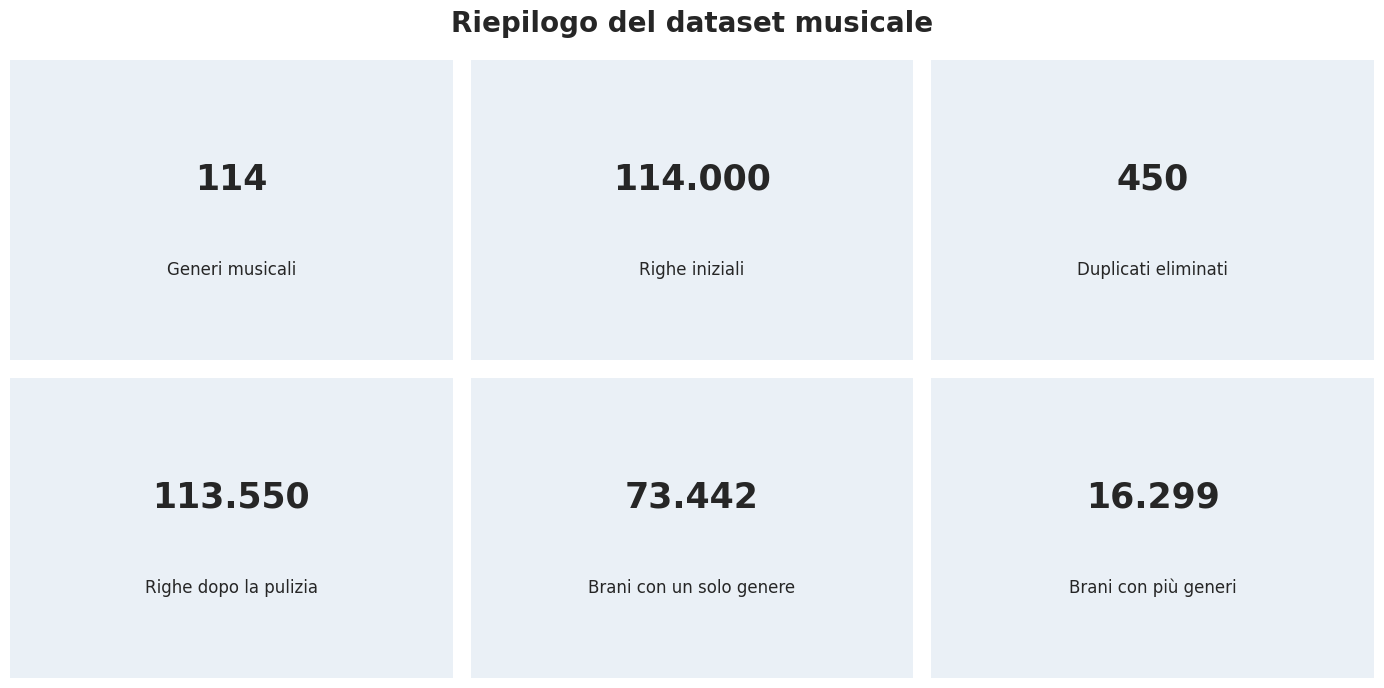

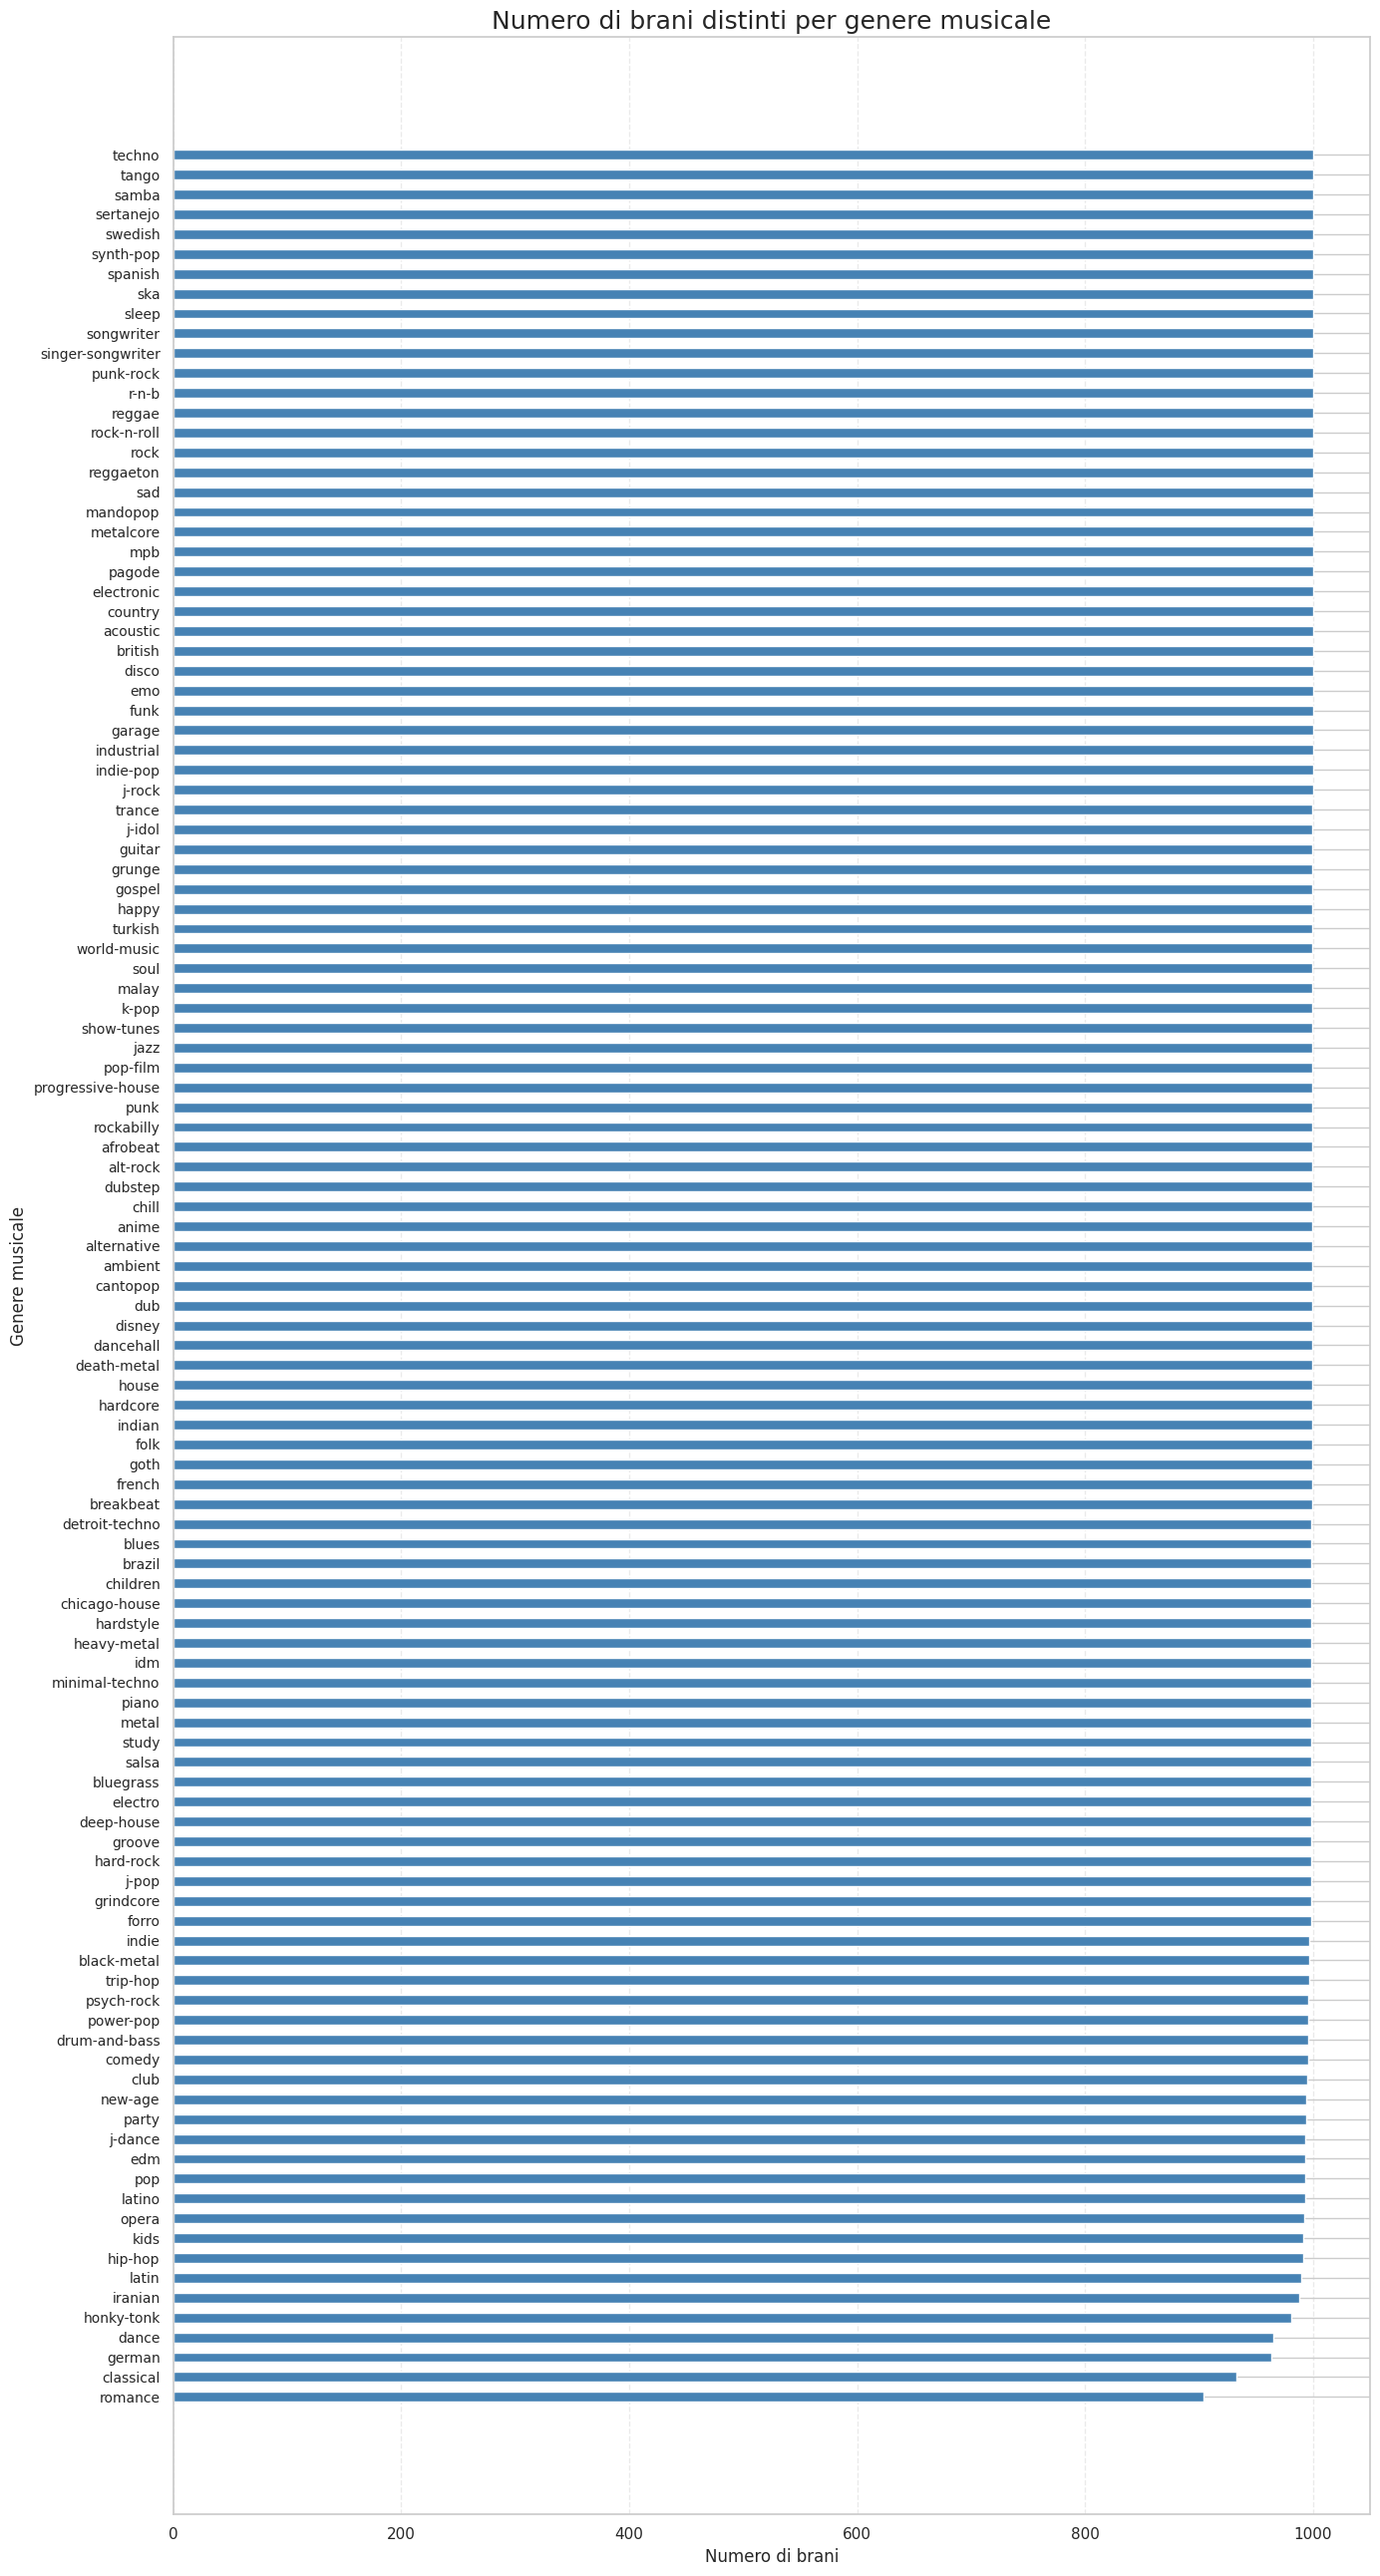

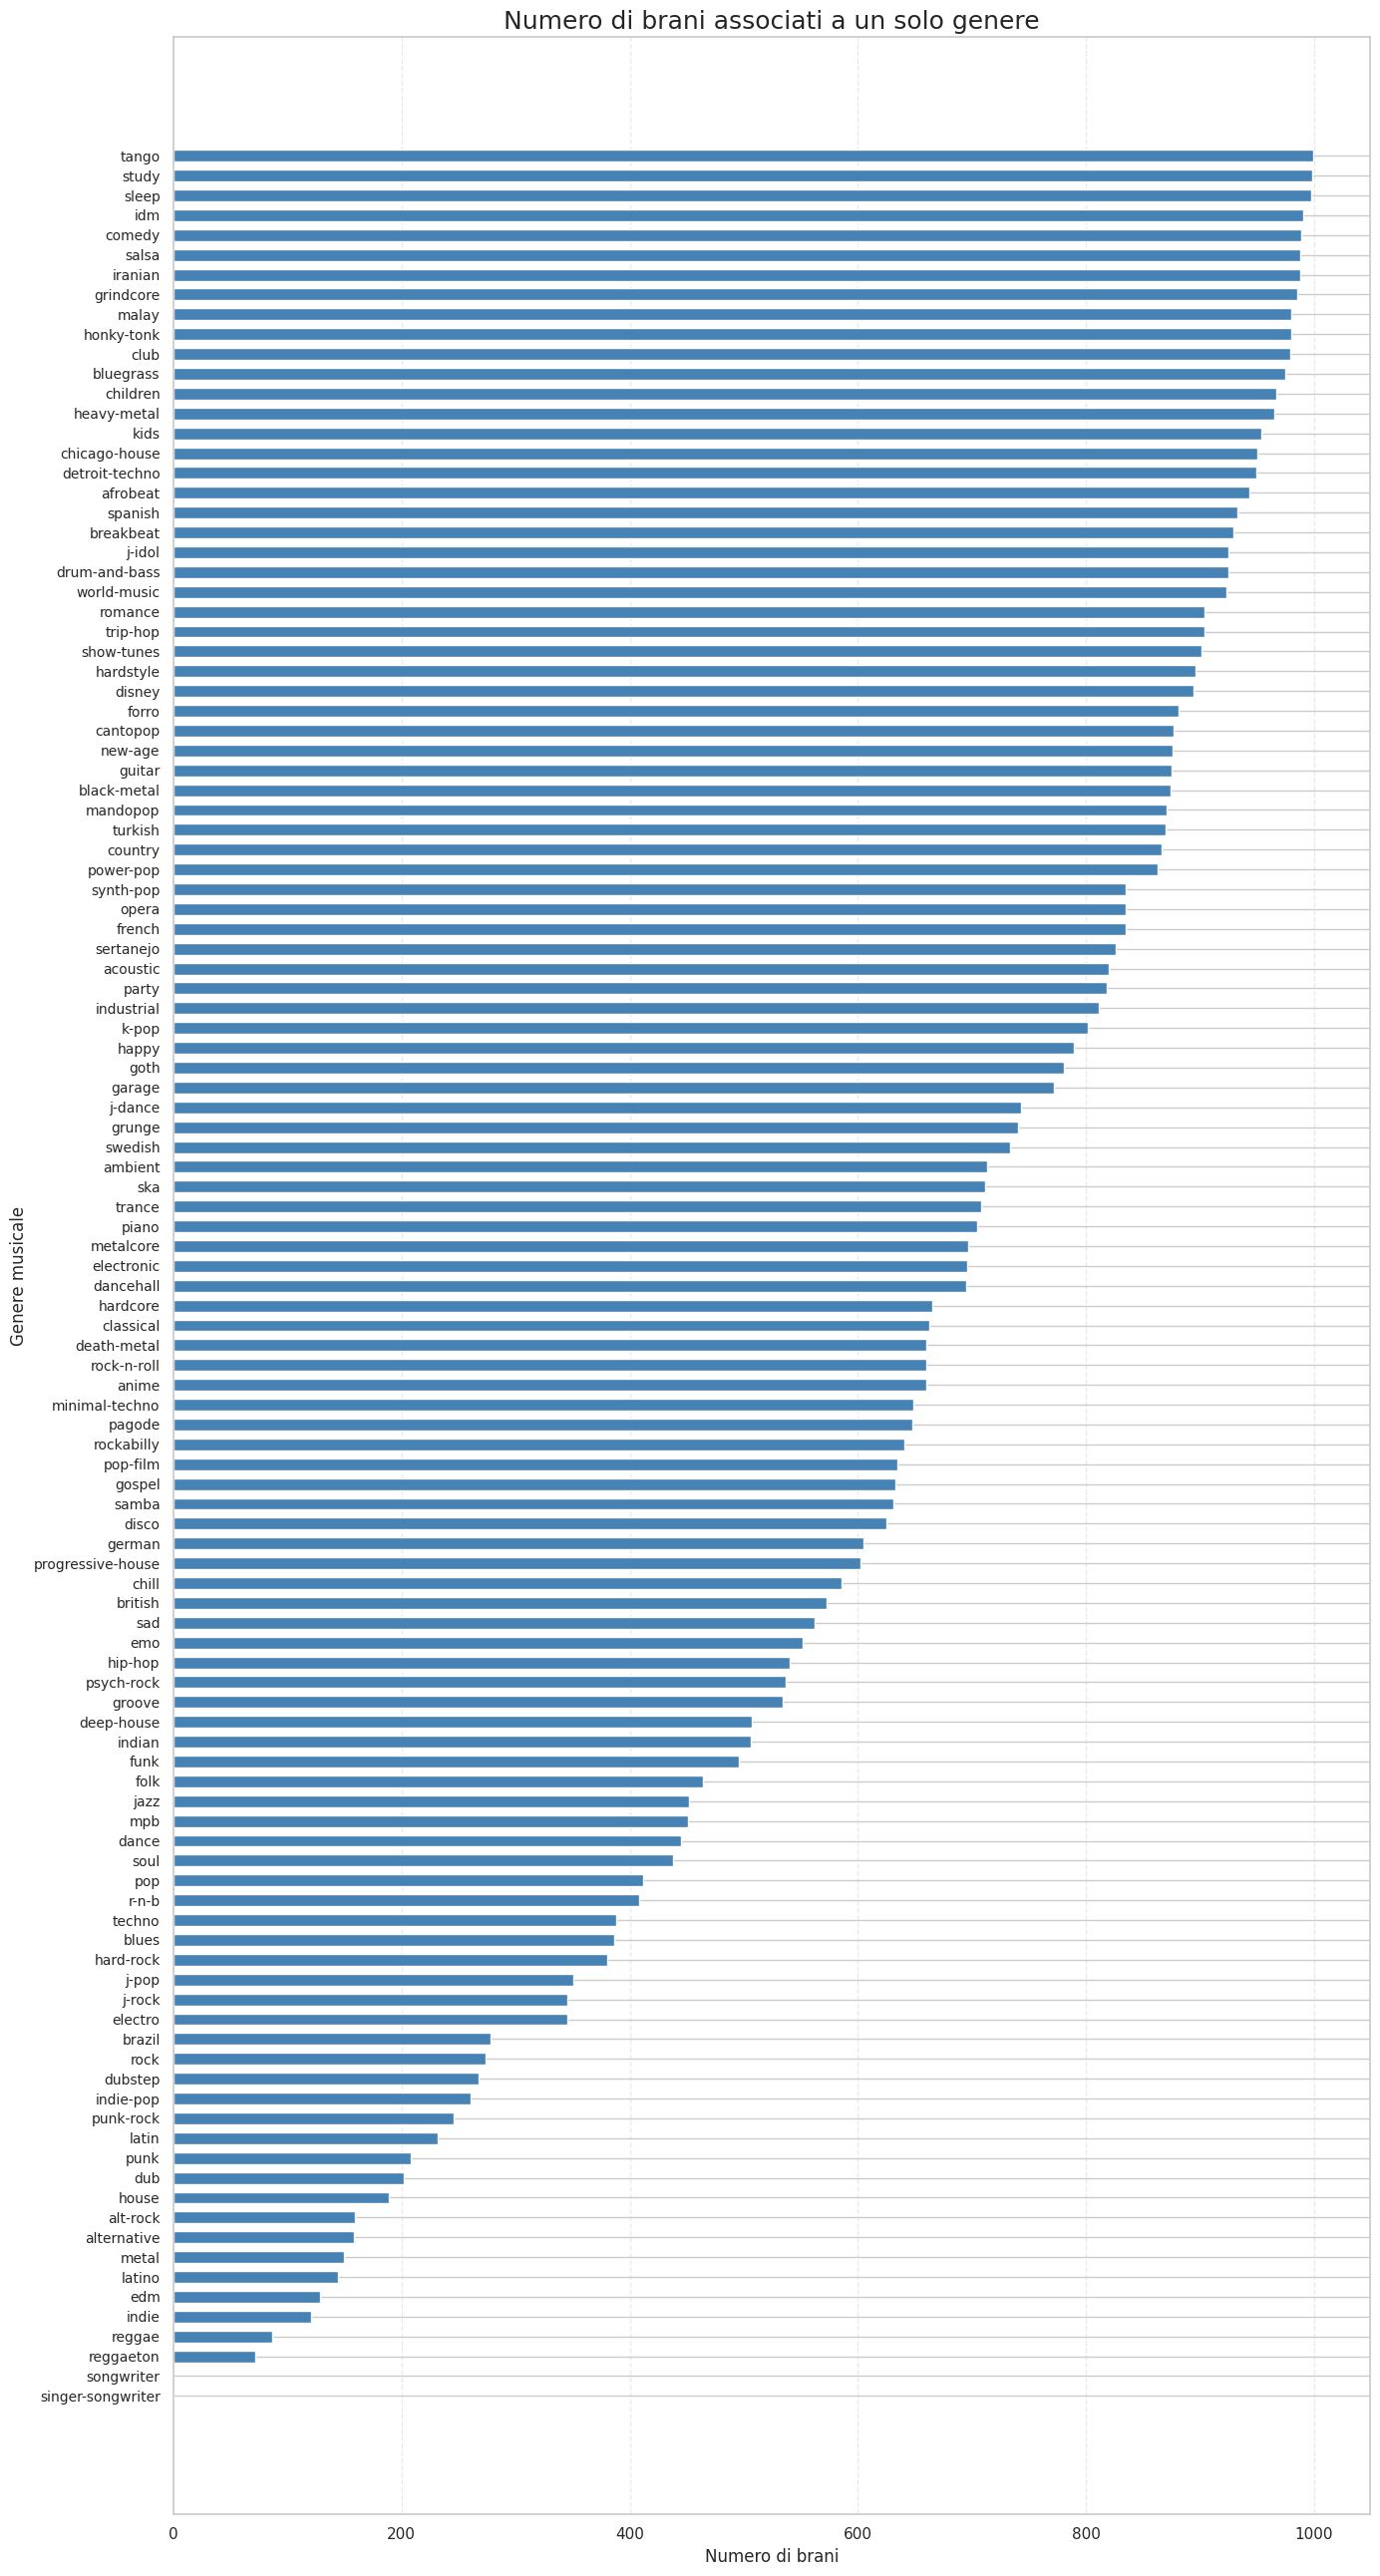

In [ ]:

# Selezione dei dati validi
df_valid = df_clean.dropna(subset=['track_id', 'track_genre']).copy()

# Numero di duplicati eliminati durante il caricamento
n_duplicates = len(df) - len(df_clean)

# Numero di righe non valide
n_invalid = len(df_clean) - len(df_valid)

# Verifica dei generi associati a ogni brano
genre_per_track = df_valid.groupby('track_id')['track_genre'].nunique()

# Conteggio dei brani distinti
n_tracks = df_valid['track_id'].nunique()

# Conteggio dei brani associati a un solo genere
n_single_genre = (genre_per_track == 1).sum()

# Conteggio dei brani associati a più generi
n_multiple_genres = (genre_per_track > 1).sum()


# CONTEGGIO DEI BRANI DISTINTI PER GENERE

genre_counts = (
    df_valid.groupby('track_genre')['track_id']
    .nunique()
    .sort_values()
)


# RIEPILOGO DEL DATASET

print("RIEPILOGO DEL DATASET")
print("-------------------------")
print("Righe iniziali:", len(df))
print("Duplicati eliminati:", n_duplicates)
print("Righe senza track_id o genere:", n_invalid)
print("Righe dopo la pulizia:", len(df_valid))
print("Numero di brani distinti:", n_tracks)
print("Brani associati a un solo genere:", n_single_genre)
print("Brani associati a più generi:", n_multiple_genres)
print("Numero di generi:", len(genre_counts))


# IMMAGINE 1: RIEPILOGO NUMERICO

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

summary = [
    (len(genre_counts), "Generi musicali"),
    (len(df), "Righe iniziali"),
    (n_duplicates, "Duplicati eliminati"),
    (len(df_valid), "Righe dopo la pulizia"),
    (n_single_genre, "Brani con un solo genere"),
    (n_multiple_genres, "Brani con più generi")
]

for ax, (value, label) in zip(axes.flat, summary):

    ax.set_facecolor('#EAF0F6')

    ax.text(
        0.5, 0.60, f"{value:,}".replace(",", "."),
        ha='center', va='center',
        fontsize=25, fontweight='bold'
    )

    ax.text(
        0.5, 0.30, label,
        ha='center', va='center',
        fontsize=12
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    'Riepilogo del dataset musicale',
    fontsize=20,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('riepilogo_generi.png', dpi=300, bbox_inches='tight')
plt.show()


# IMMAGINE 2: NUMERO DI BRANI DISTINTI PER GENERE

plt.figure(figsize=(14, 26))

# Impostazioni del Bar Chart
plt.barh(
    genre_counts.index,
    genre_counts.values,
    color='steelblue',
    height=0.5
)

plt.title('Numero di brani distinti per genere musicale', fontsize=18)
plt.xlabel('Numero di brani')
plt.ylabel('Genere musicale')

plt.yticks(fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('distribuzione_generi.png', dpi=300, bbox_inches='tight')
plt.show()


# IMMAGINE 3: BRANI ASSOCIATI A UN SOLO GENERE

# Selezione dei brani associati a un solo genere
single_genre_ids = genre_per_track[genre_per_track == 1].index

df_single_genre = df_valid[
    df_valid['track_id'].isin(single_genre_ids)
].drop_duplicates(subset='track_id').copy()

# Conteggio dei brani per genere
single_genre_counts = (
    df_single_genre.groupby('track_genre')['track_id']
    .nunique()
    .reindex(genre_counts.index, fill_value=0)
    .sort_values()
)

# Impostazioni del Bar Chart
plt.figure(figsize=(14, 26))

plt.barh(
    single_genre_counts.index,
    single_genre_counts.values,
    color='steelblue',
    height=0.6
)

plt.title('Numero di brani associati a un solo genere', fontsize=18)
plt.xlabel('Numero di brani')
plt.ylabel('Genere musicale')

plt.yticks(fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('brani_genere_unico.png', dpi=300, bbox_inches='tight')
plt.show()


# DOWNLOAD DELLE IMMAGINI

#from google.colab import files

#files.download('riepilogo_generi.png')

#files.download('distribuzione_generi.png')
#files.download('brani_genere_unico.png')


#### 4.1.2 Distribuzione delle caratteristiche musicali

- **Tipo di grafico:** Istogrammi, possibilmente.
- **Dati utilizzati:**
  - `danceability`
  - `energy`
  - `valence`
  - `acousticness`
  - `instrumentalness`
  - `speechiness`
  - `tempo`
  - `loudness`
  - `liveness`

- **Obiettivo:**
  - Analizzare la distribuzione delle nove caratteristiche musicali.
  - Individuare gli intervalli di valori più frequenti.
  - Osservare eventuali distribuzioni asimmetriche e valori estremi.

- **Motivazione:**
  - L'istogramma è adatto a rappresentare la distribuzione di una variabile numerica e permette di osservare la frequenza dei diversi intervalli di valori.
  - Consente di individuare eventuali asimmetrie, concentrazioni di valori e distribuzioni particolari.
  - L'utilizzo degli Small Multiples permette di confrontare le nove caratteristiche attraverso grafici separati, mantenendo una visualizzazione ordinata e facilmente leggibile.
  - Questa analisi è importante per comprendere le variabili che verranno utilizzate successivamente nel clustering.
  

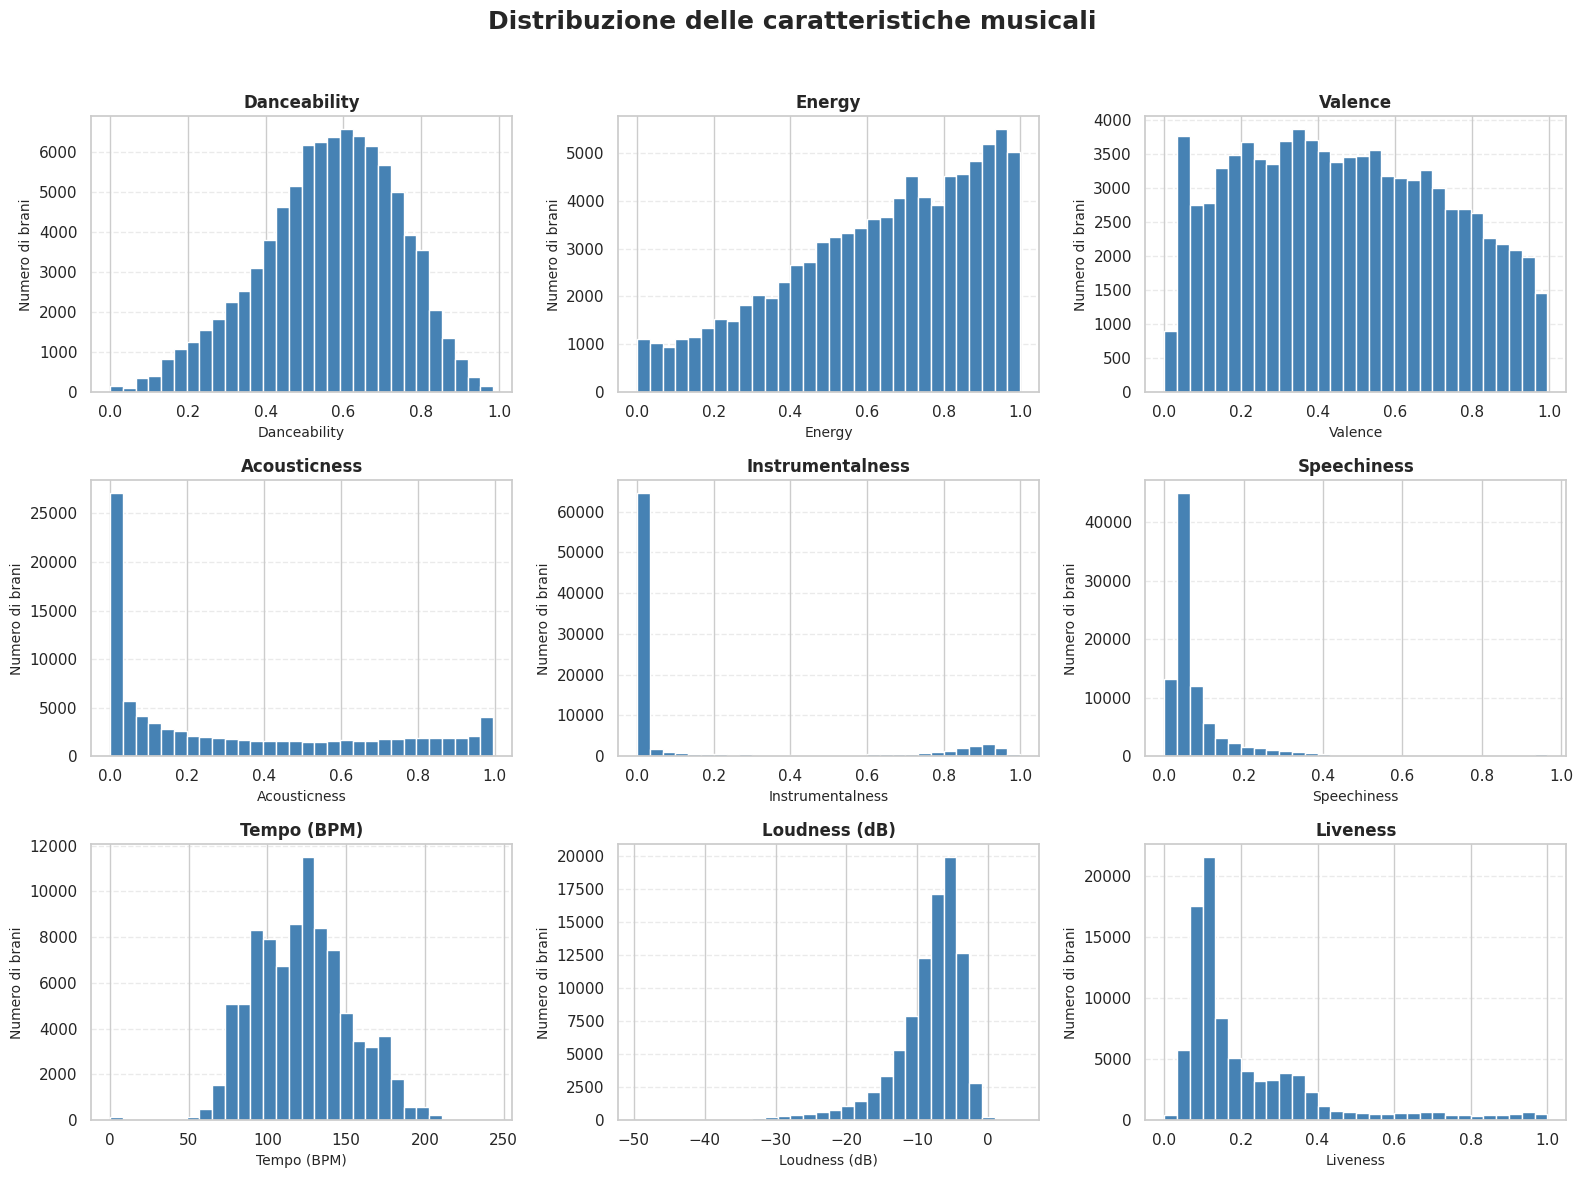

In [ ]:

# ============================================================
# 1. PREPARAZIONE DEI DATI
# ============================================================

# Utilizzo dei dati audio già selezionati nella cella 10
# Ogni brano viene considerato una sola volta

X_eda = X_audio[features].copy()

# Conversione dei valori in formato numerico

X_eda = X_eda.apply(
    pd.to_numeric,
    errors='coerce'
)

# Gestione di eventuali valori infiniti

X_eda = X_eda.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 2. DISTRIBUZIONE DELLE CARATTERISTICHE MUSICALI
# ============================================================

# Nomi da utilizzare nei grafici

nomi_caratteristiche = {
    'danceability': 'Danceability',
    'energy': 'Energy',
    'valence': 'Valence',
    'acousticness': 'Acousticness',
    'instrumentalness': 'Instrumentalness',
    'speechiness': 'Speechiness',
    'tempo': 'Tempo (BPM)',
    'loudness': 'Loudness (dB)',
    'liveness': 'Liveness'
}

# Creazione di una griglia 3x3

fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 12)
)

# Generazione di un istogramma per ogni caratteristica

for ax, caratteristica in zip(axes.flat, features):

    # Selezione dei valori disponibili

    valori = X_eda[caratteristica].dropna()

    # Generazione dell'istogramma

    ax.hist(
        valori,
        bins=30,
        color='steelblue',
        edgecolor='white'
    )

    # Titolo del grafico

    ax.set_title(
        nomi_caratteristiche[caratteristica],
        fontsize=12,
        fontweight='bold'
    )

    # Etichette degli assi

    ax.set_xlabel(
        nomi_caratteristiche[caratteristica],
        fontsize=10
    )

    ax.set_ylabel(
        'Numero di brani',
        fontsize=10
    )

    # Griglia per facilitare la lettura

    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.4
    )

# Titolo generale

fig.suptitle(
    'Distribuzione delle caratteristiche musicali',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

# Salvataggio del grafico

plt.savefig(
    'distribuzione_caratteristiche_audio.png',
    dpi=300,
    bbox_inches='tight'
)

# Visualizzazione

plt.show()


#### 4.1.3 Correlazione tra le caratteristiche musicali

- **Tipo di grafico:** Correlation Heatmap.
- **Dati utilizzati:** le otto caratteristiche musicali del grafico precedente.

- **Obiettivo:**
  - Individuare le caratteristiche che tendono a variare insieme.
  - Analizzare eventuali correlazioni positive o negative.
  - Verificare se alcune variabili descrivono aspetti musicali simili.

- **Motivazione:**
  - La Heatmap utilizza una scala di colori per rappresentare l'intensità e la direzione delle correlazioni tra le variabili.
  - Permette di confrontare rapidamente tutte le coppie di caratteristiche musicali.
  - È particolarmente adatta quando si devono analizzare più variabili contemporaneamente, perché rende le relazioni più immediate rispetto a una semplice tabella numerica.
  - Questa visualizzazione aiuta a comprendere le relazioni tra le caratteristiche che verranno utilizzate nel clustering.

MATRICE DI CORRELAZIONE
-------------------------
Brani analizzati: 89741
Caratteristiche analizzate: 9


,danceability,energy,valence,acousticness,instrumentalness,speechiness,tempo,loudness,liveness
danceability,1.000000,0.143914,0.492571,-0.177043,-0.194747,0.109520,-0.021331,0.271839,-0.132234
energy,0.143914,1.000000,0.256313,-0.732566,-0.181037,0.141332,0.258628,0.758774,0.188941
valence,0.492571,0.256313,1.000000,-0.103767,-0.330759,0.032932,0.090622,0.289091,0.012314
acousticness,-0.177043,-0.732566,-0.103767,1.000000,0.096065,0.005121,-0.220244,-0.582663,-0.019081
instrumentalness,-0.194747,-0.181037,-0.330759,0.096065,1.000000,-0.099658,-0.056888,-0.434717,-0.087152
speechiness,0.109520,0.141332,0.032932,0.005121,-0.099658,1.000000,0.004032,0.055295,0.225102
tempo,-0.021331,0.258628,0.090622,-0.220244,-0.056888,0.004032,1.000000,0.228659,-0.006117
loudness,0.271839,0.758774,0.289091,-0.582663,-0.434717,0.055295,0.228659,1.000000,0.077239
liveness,-0.132234,0.188941,0.012314,-0.019081,-0.087152,0.225102,-0.006117,0.077239,1.000000


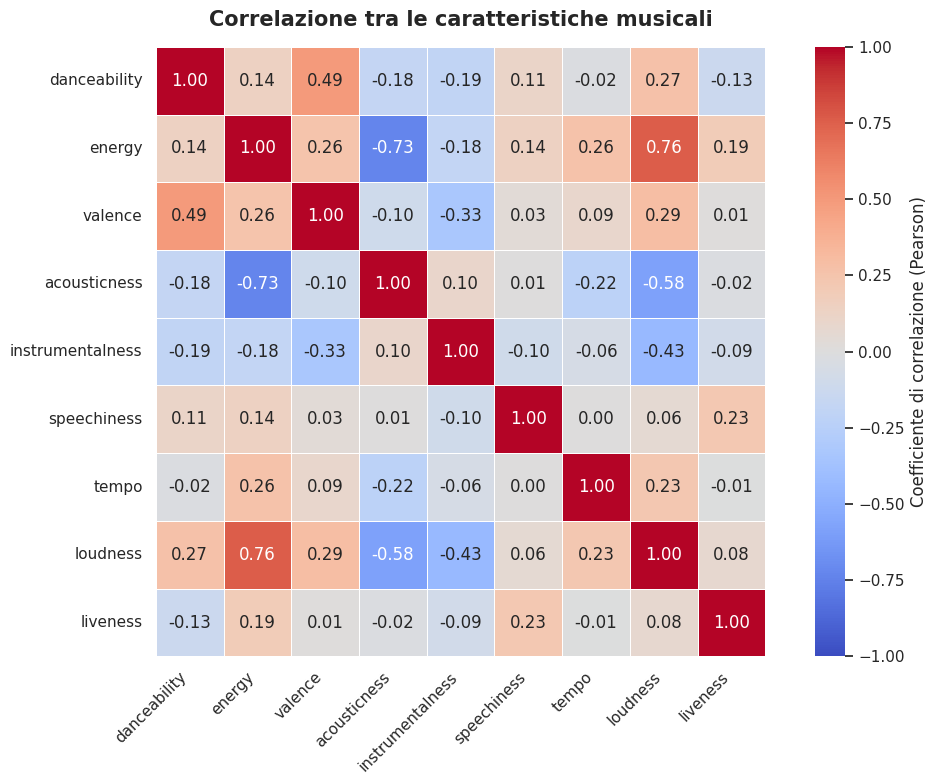

In [ ]:
# 1. SELEZIONE DELLE CARATTERISTICHE AUDIO

# Utilizzo dei brani distinti già selezionati
X_corr = df_tracks[features].copy()

# Conversione dei valori in formato numerico
X_corr = X_corr.apply(pd.to_numeric, errors='coerce')

# Gestione dei valori mancanti e infiniti
X_corr = X_corr.replace([np.inf, -np.inf], np.nan)
X_corr = X_corr.dropna()


# 2. CALCOLO DELLA MATRICE DI CORRELAZIONE

correlation_matrix = X_corr.corr(method='pearson')

print("MATRICE DI CORRELAZIONE")
print("-------------------------")
print("Brani analizzati:", len(X_corr))
print("Caratteristiche analizzate:", len(features))

display(correlation_matrix)


# 3. GENERAZIONE DELLA CORRELATION HEATMAP

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={
        'label': 'Coefficiente di correlazione (Pearson)'
    }
)

plt.title(
    'Correlazione tra le caratteristiche musicali',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### 4.1.4 Differenze delle caratteristiche musicali tra generi (Facolatativo)
- **Tipo di grafico:** Box Plot.
- **Dati utilizzati:**
  - `track_genre`
  - Un sottoinsieme delle otto caratteristiche musicali.

- **Obiettivo:**
  - Confrontare le caratteristiche musicali tra diversi generi.
  - Osservare mediane, dispersione e valori estremi.
  - Individuare eventuali somiglianze e differenze tra le categorie musicali.

- **Motivazione:**
  - Il Box Plot permette di rappresentare la distribuzione di una variabile numerica attraverso mediana, quartili e valori anomali.
  - Consente di confrontare contemporaneamente le distribuzioni di una caratteristica tra diversi generi.
  - È utile per osservare eventuali differenze e sovrapposizioni tra le categorie originali.
  - Questa visualizzazione costituisce un primo approfondimento sulle caratteristiche acustiche dei generi, che verranno successivamente confrontati con i cluster individuati.

PREPARAZIONE DEI DATI
--------------------------------
Osservazioni disponibili: 113550
Brani distinti: 89741
Generi musicali individuati: 114
Caratteristiche audio: 9

OSSERVAZIONI DISPONIBILI PER GENERE E CARATTERISTICA


,danceability,energy,valence,acousticness,instrumentalness,speechiness,tempo,loudness,liveness
track_genre,,,,,,,,,
acoustic,1000,1000,1000,1000,1000,1000,1000,1000,1000
afrobeat,999,999,999,999,999,999,999,999,999
alt-rock,999,999,999,999,999,999,999,999,999
alternative,999,999,999,999,999,999,999,999,999
ambient,999,999,999,999,999,999,999,999,999
...,...,...,...,...,...,...,...,...,...
techno,1000,1000,1000,1000,1000,1000,1000,1000,1000
trance,999,999,999,999,999,999,999,999,999
trip-hop,997,997,997,997,997,997,997,997,997


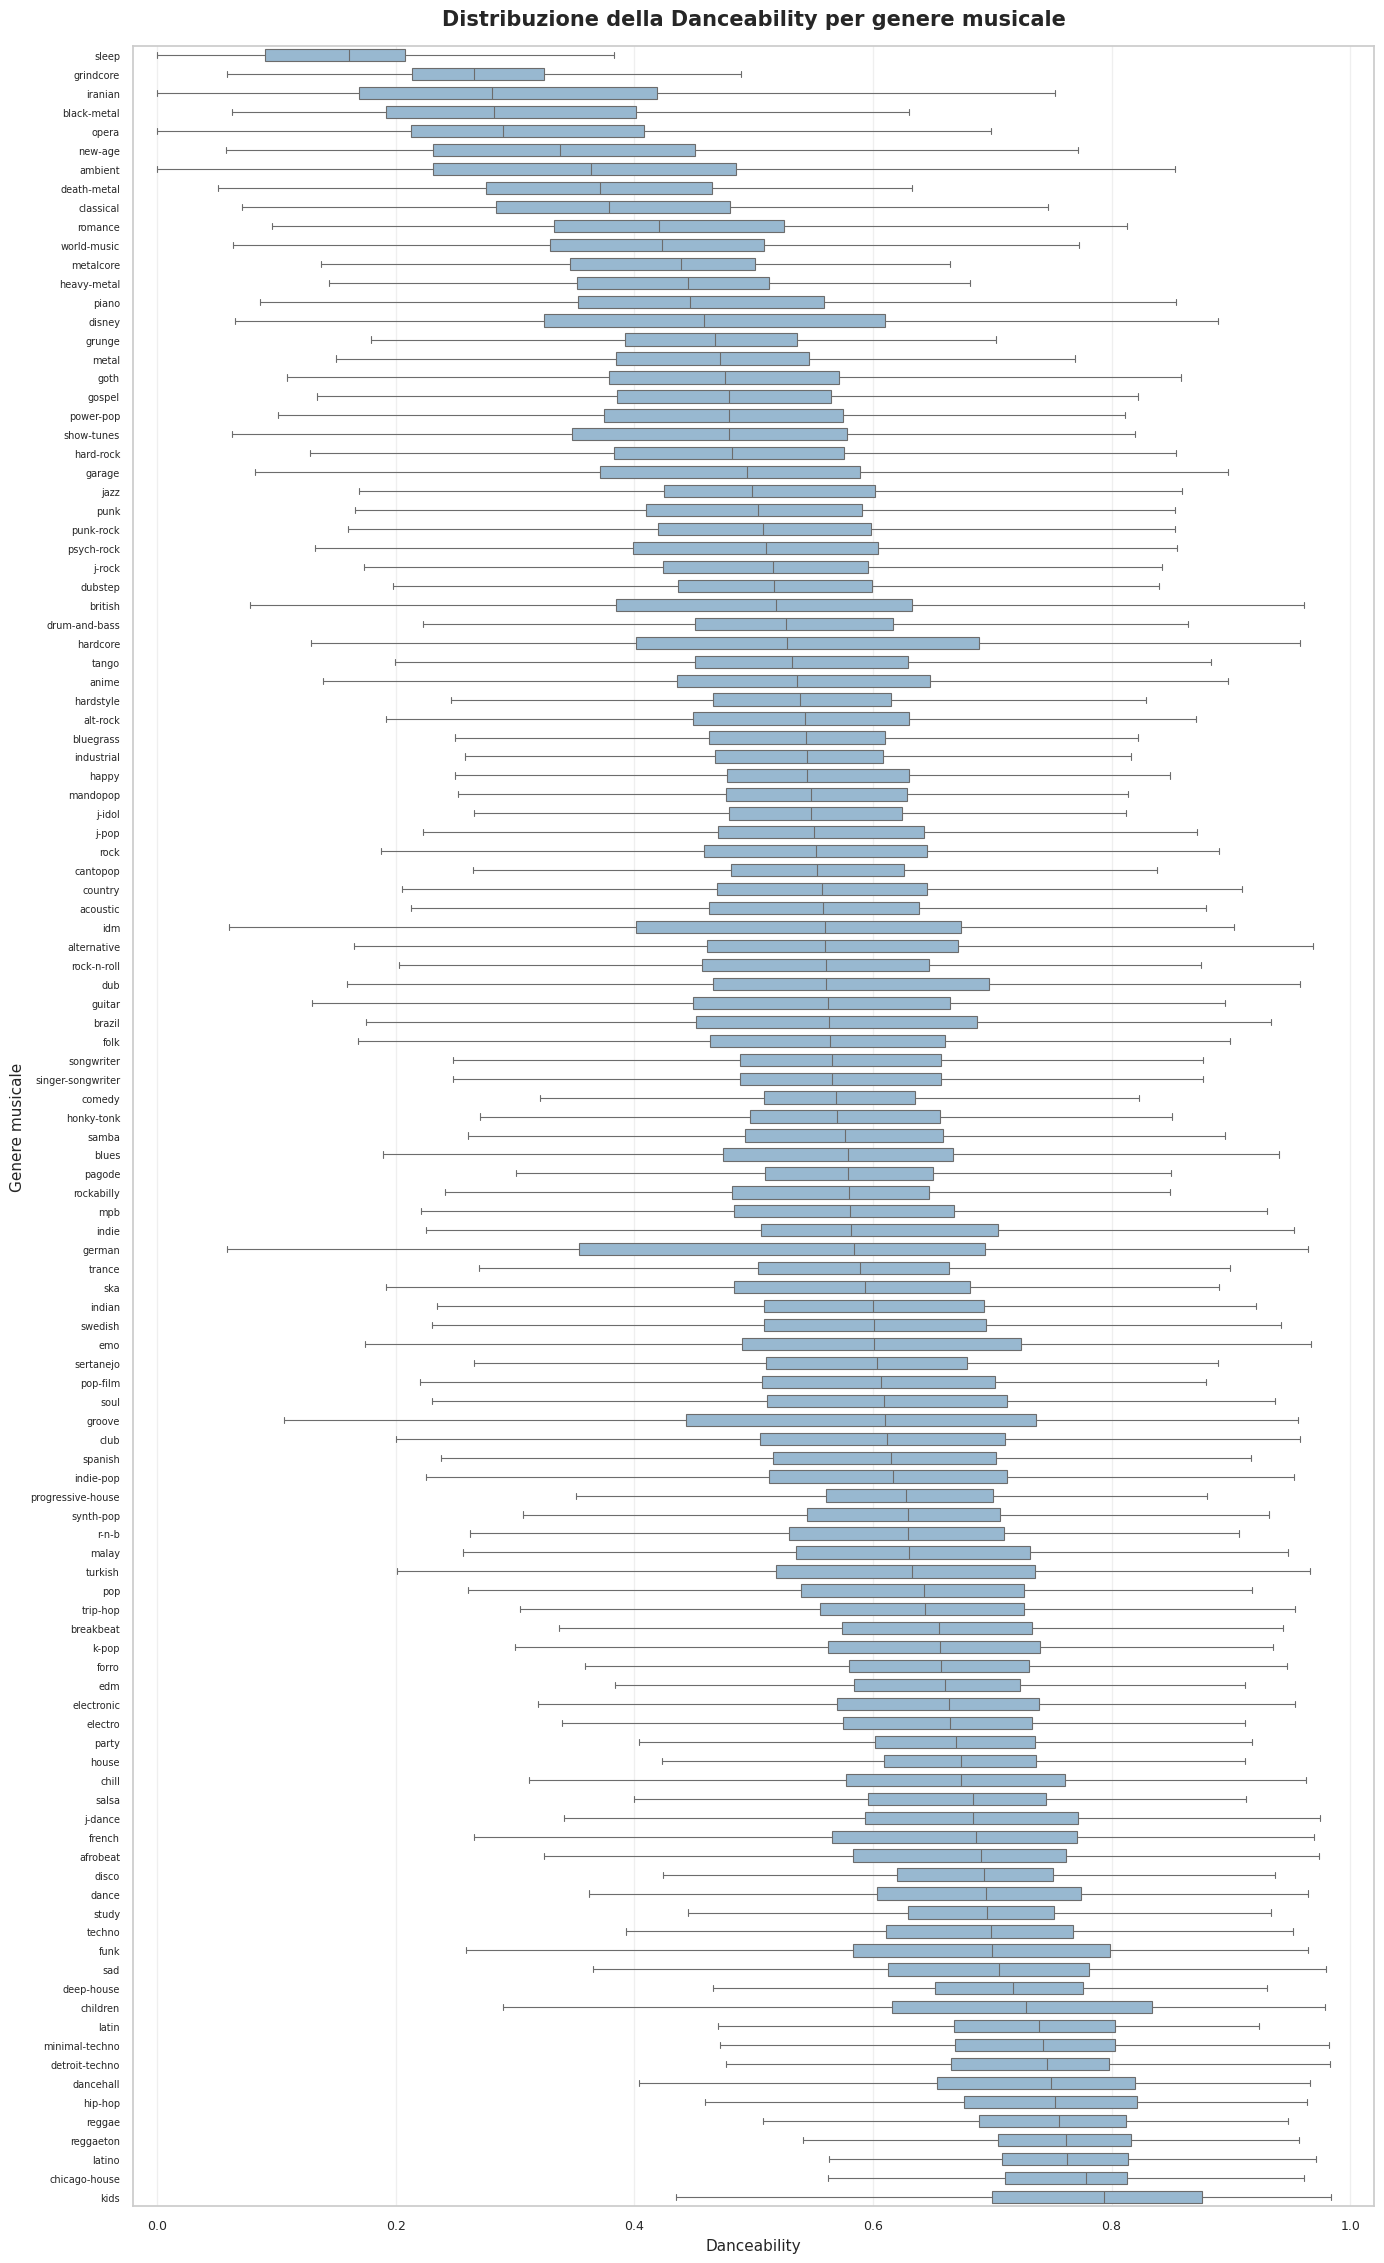

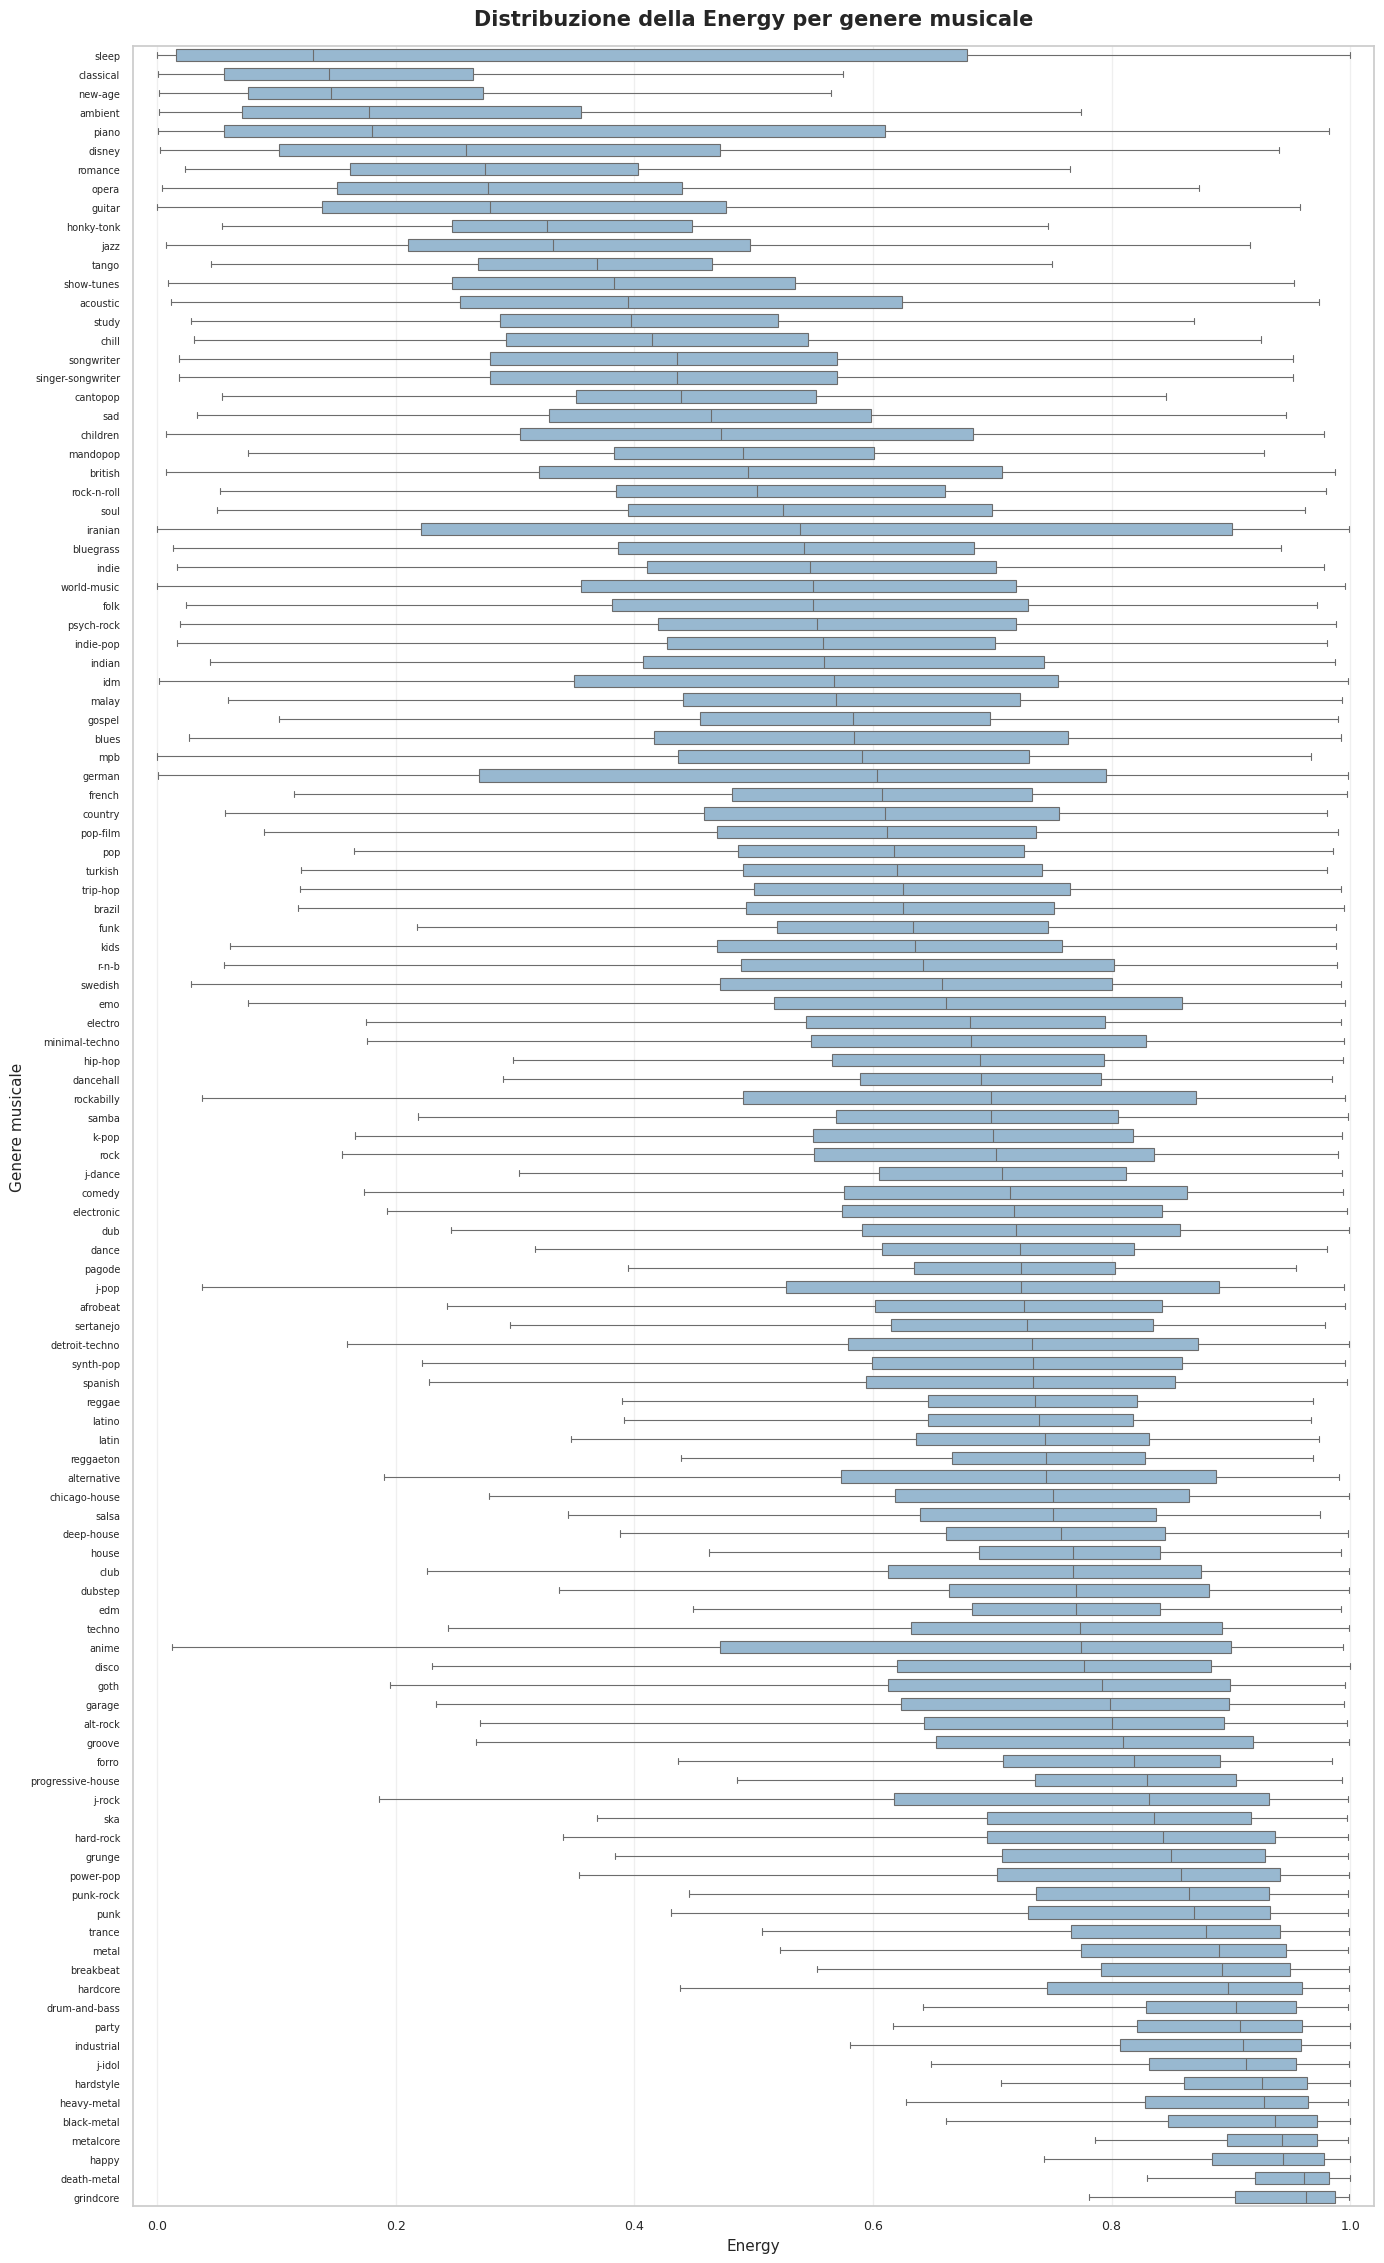

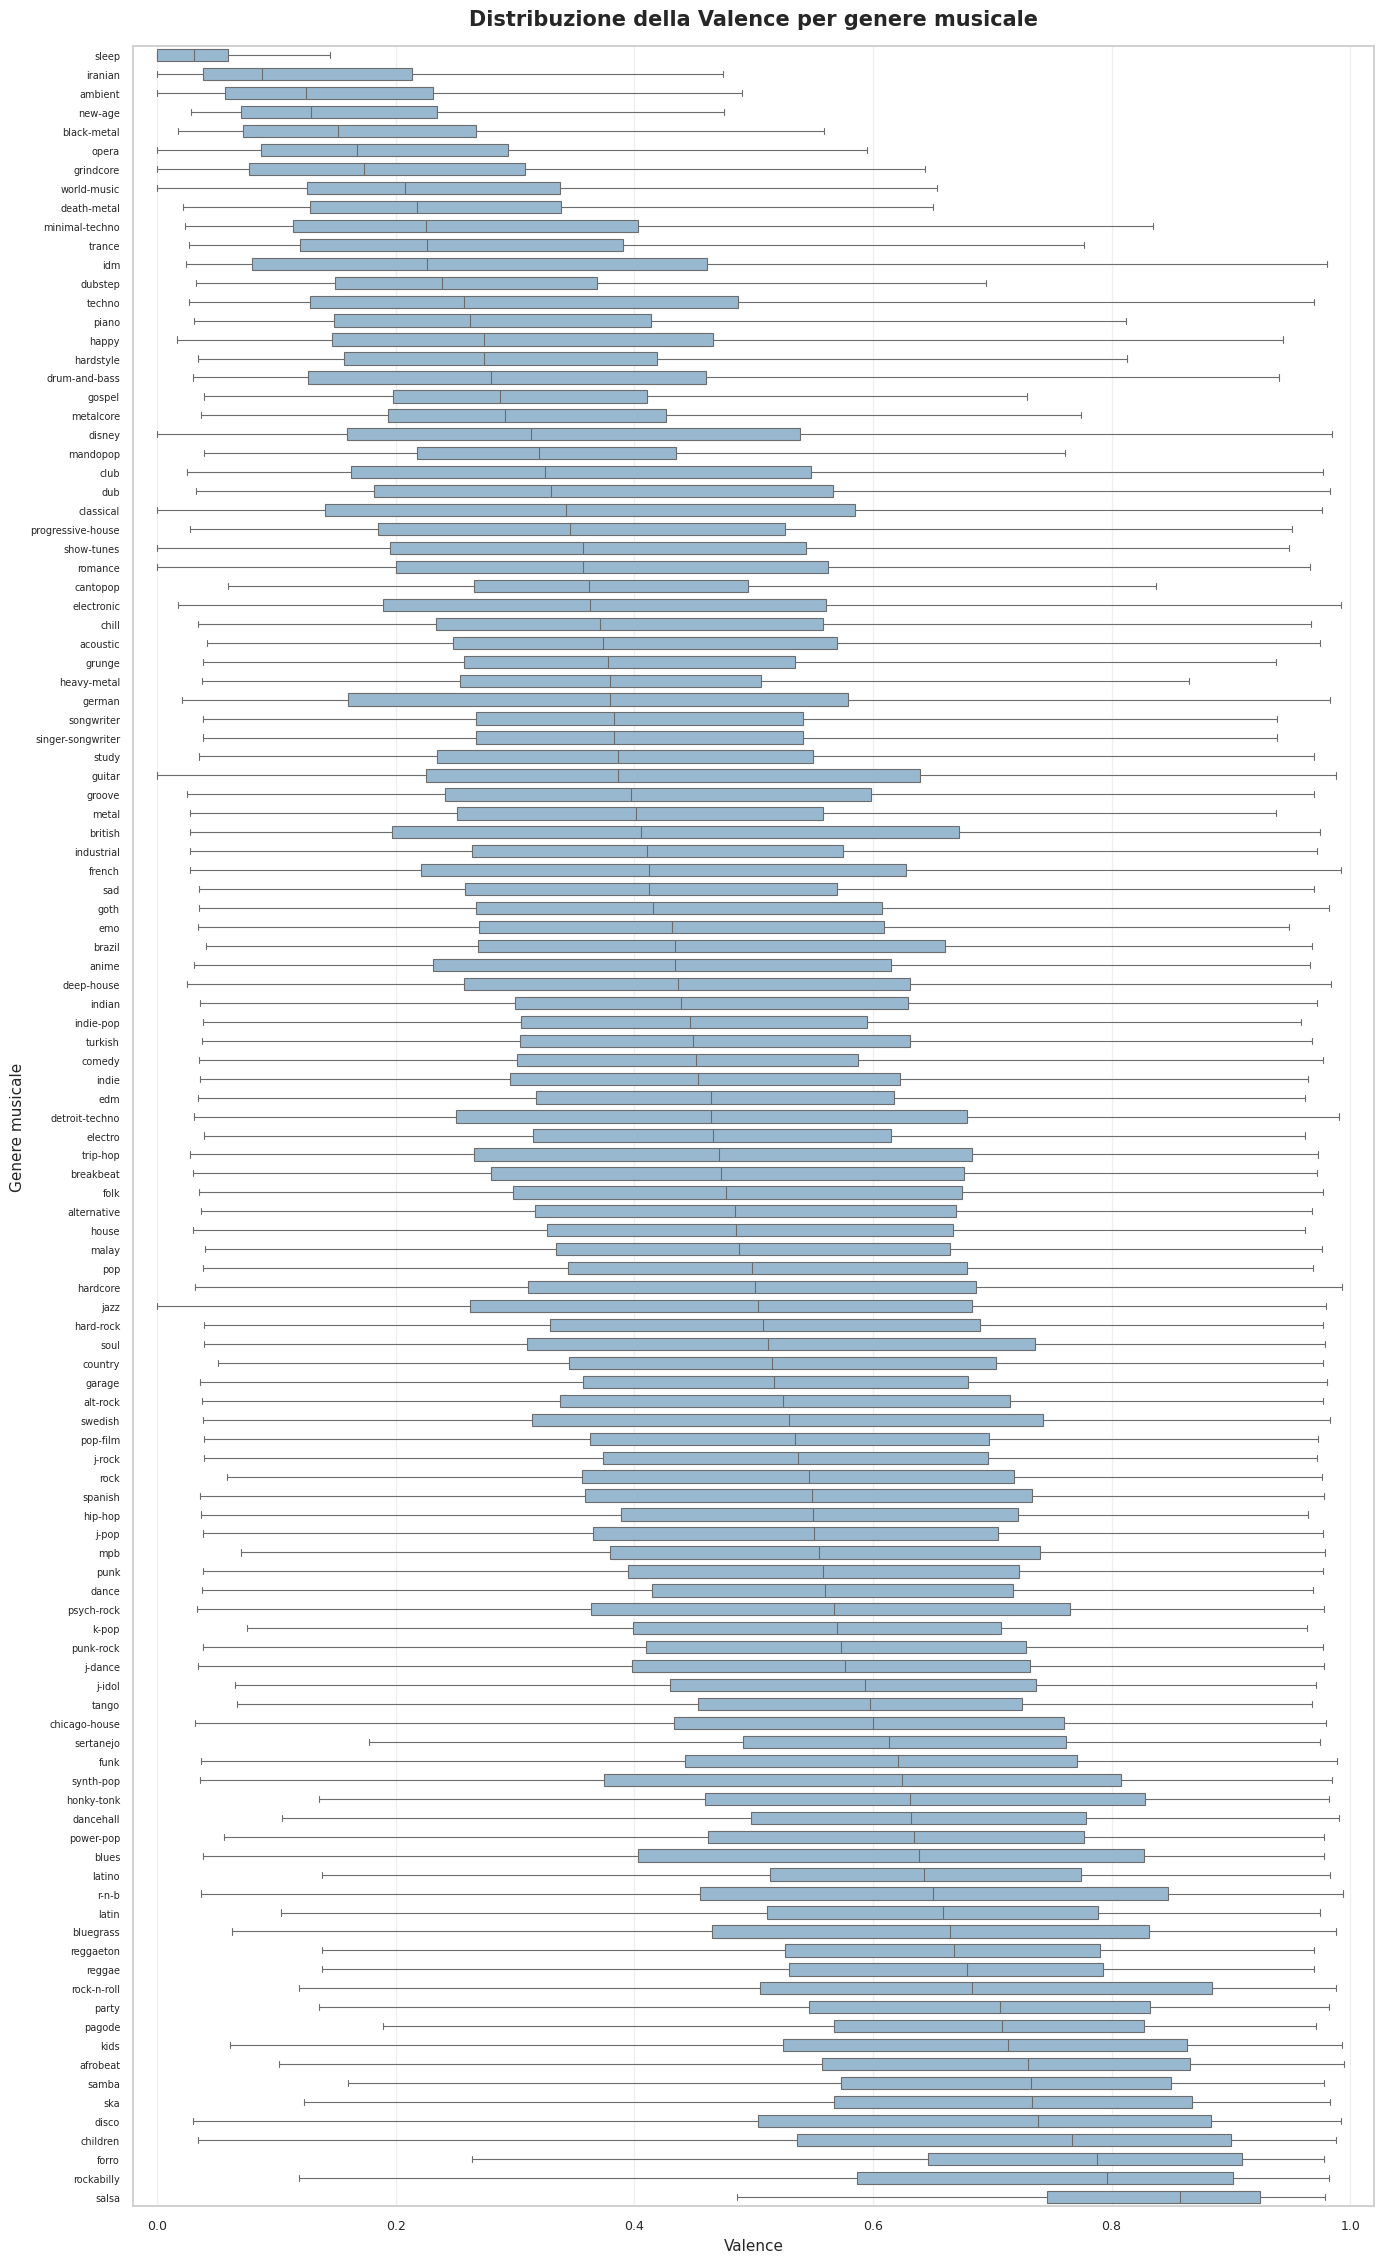

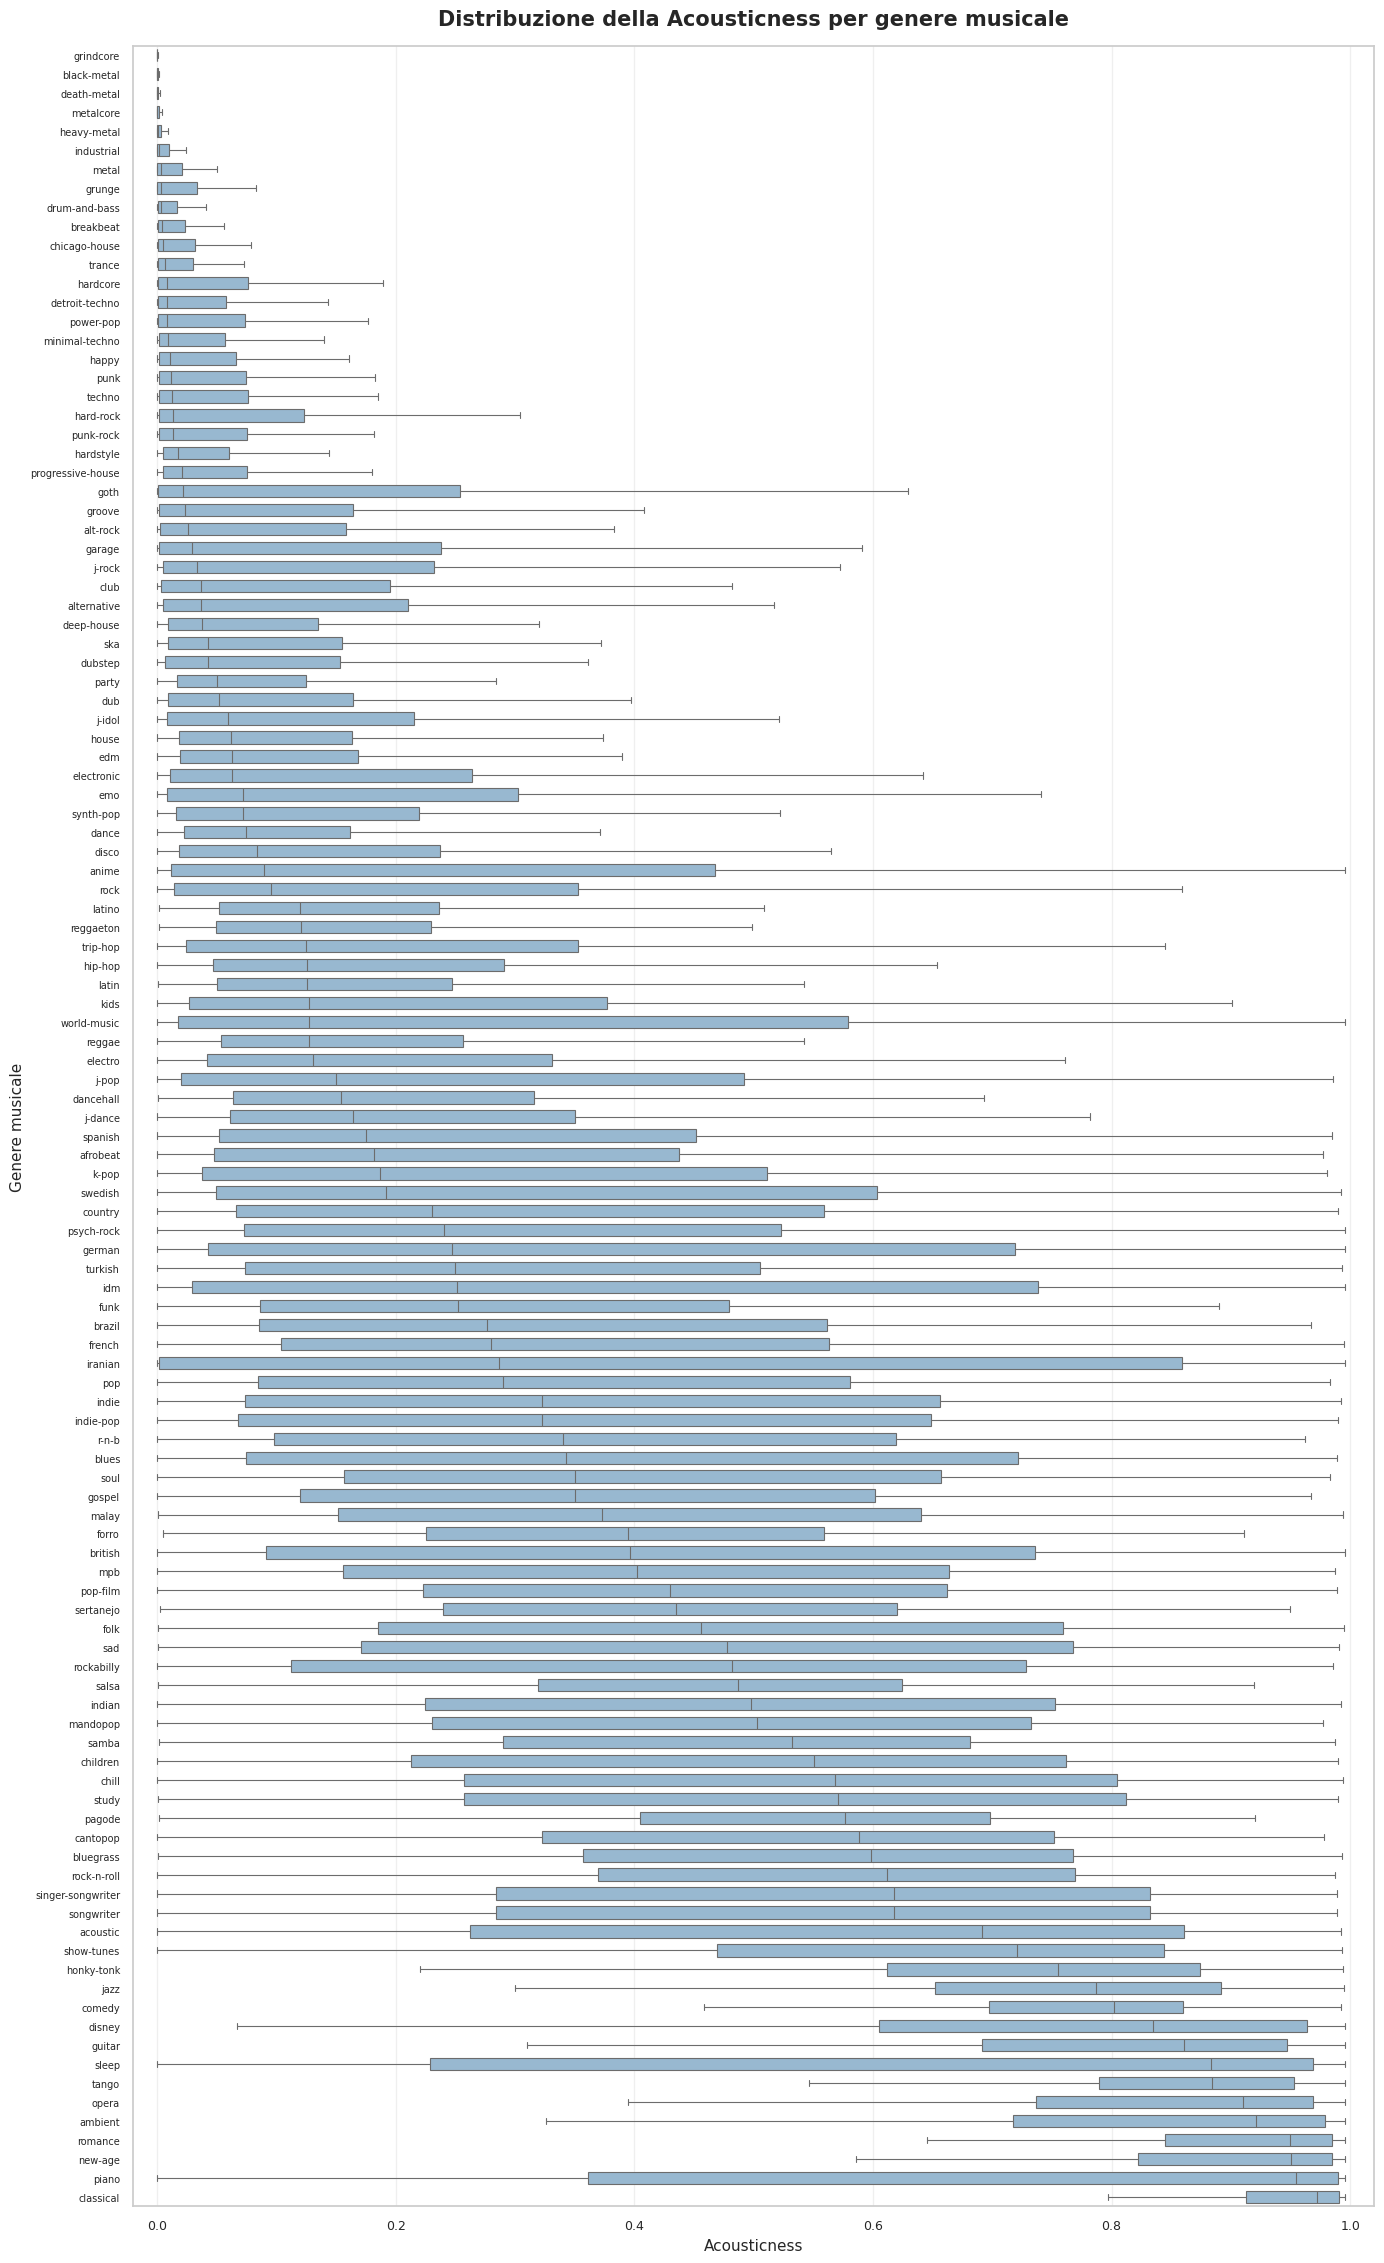

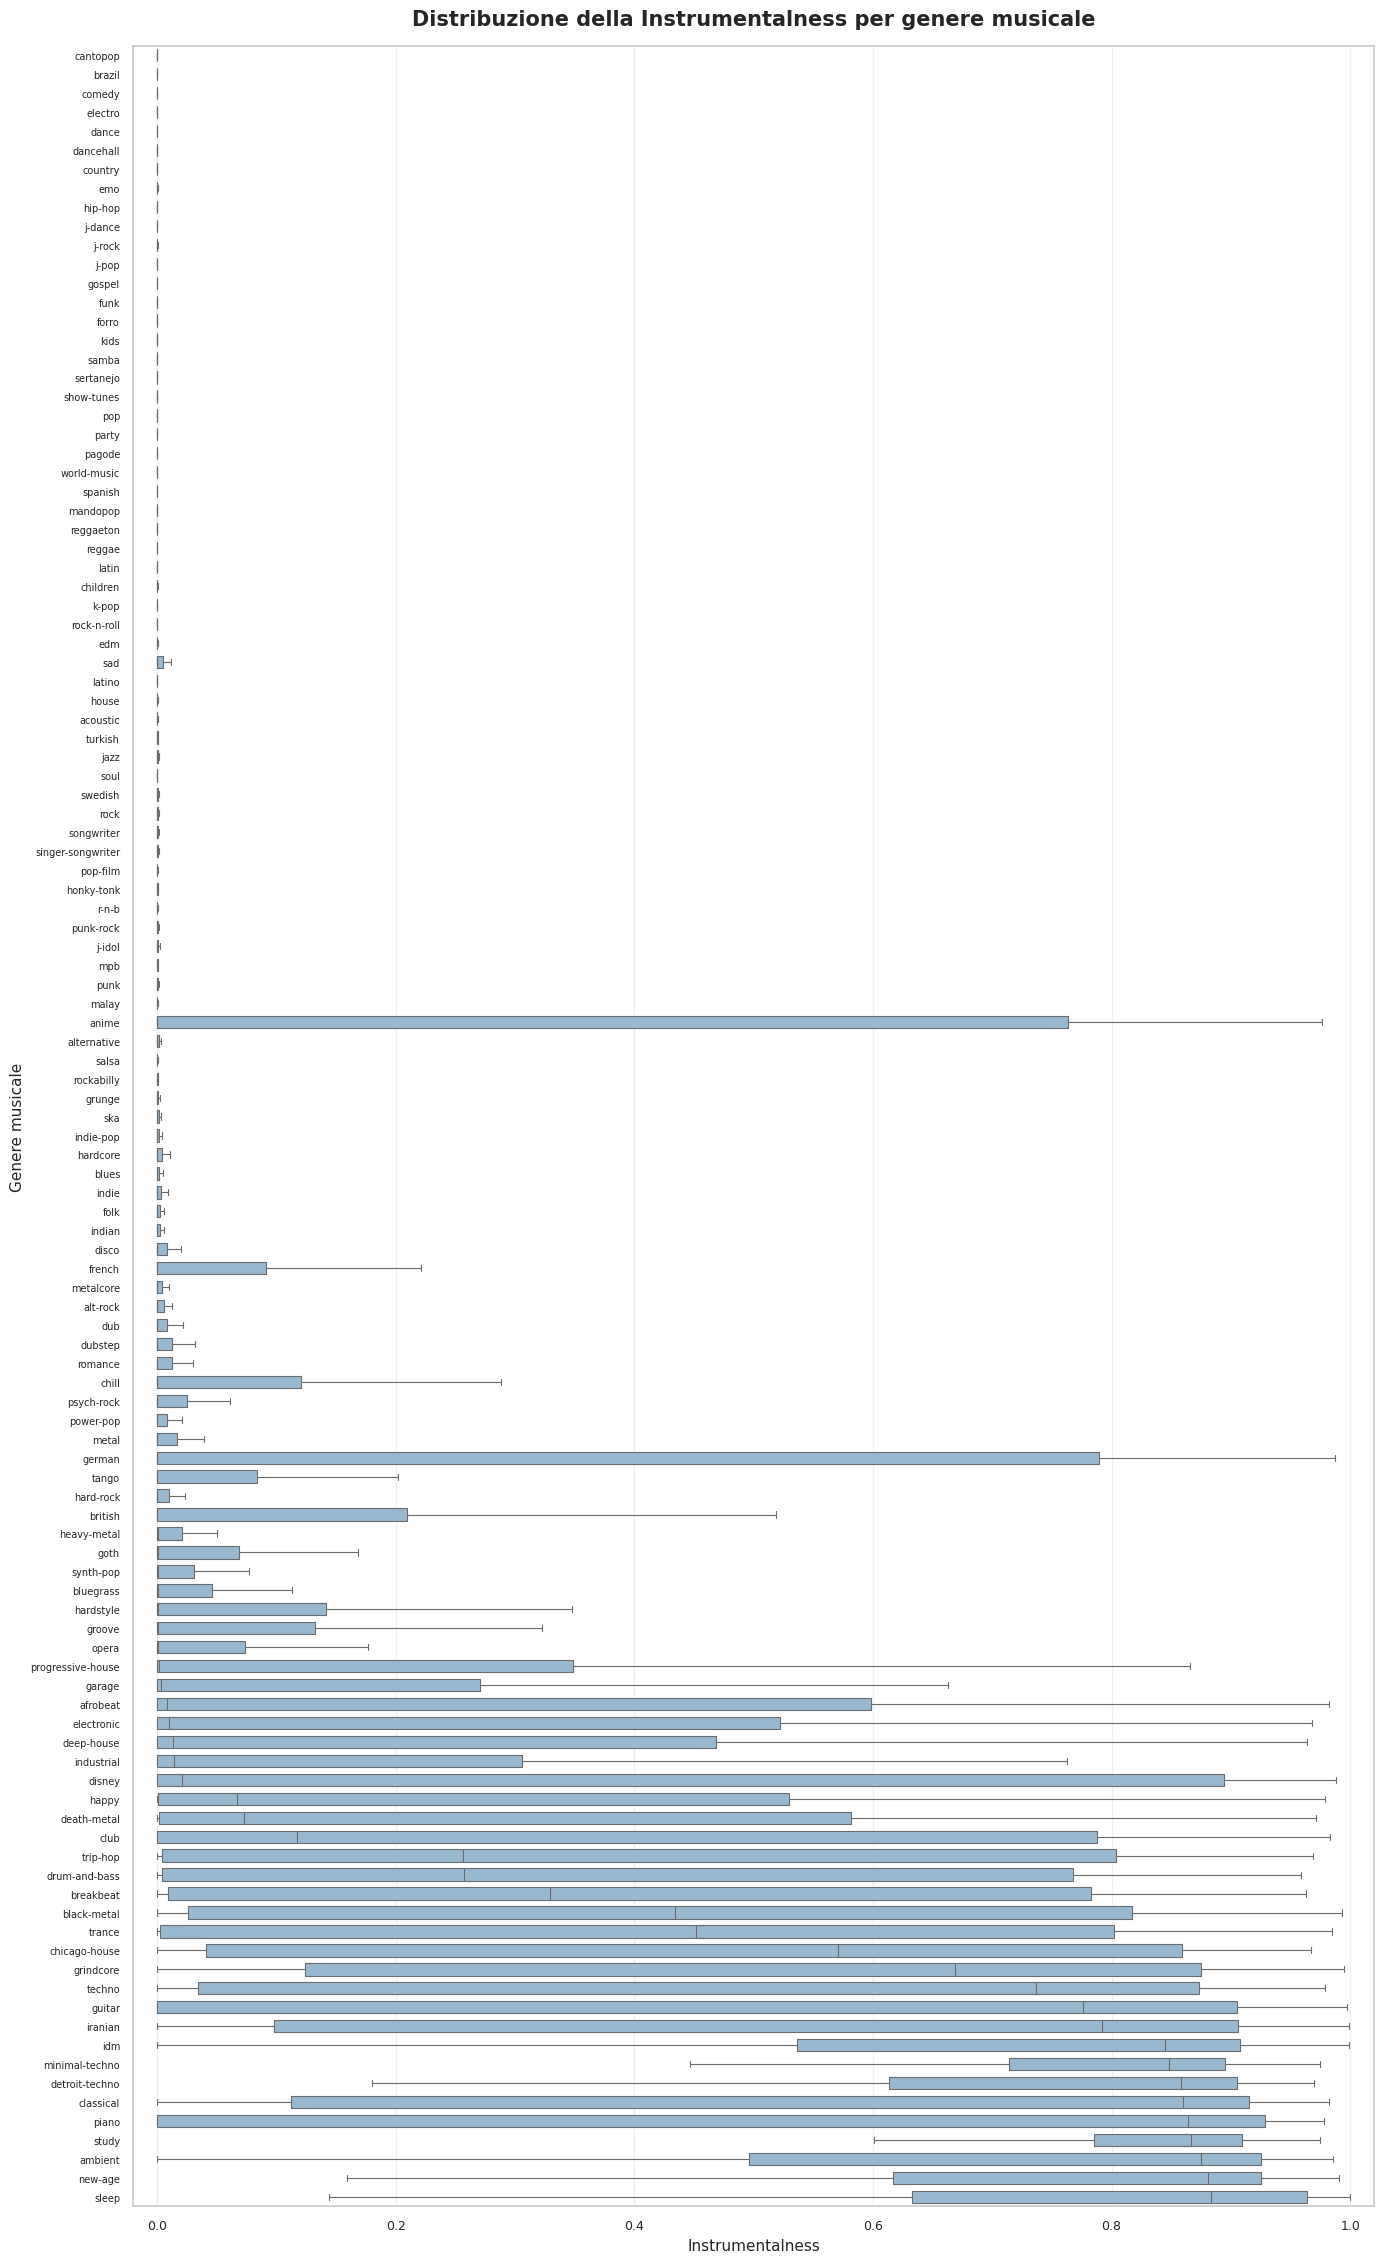

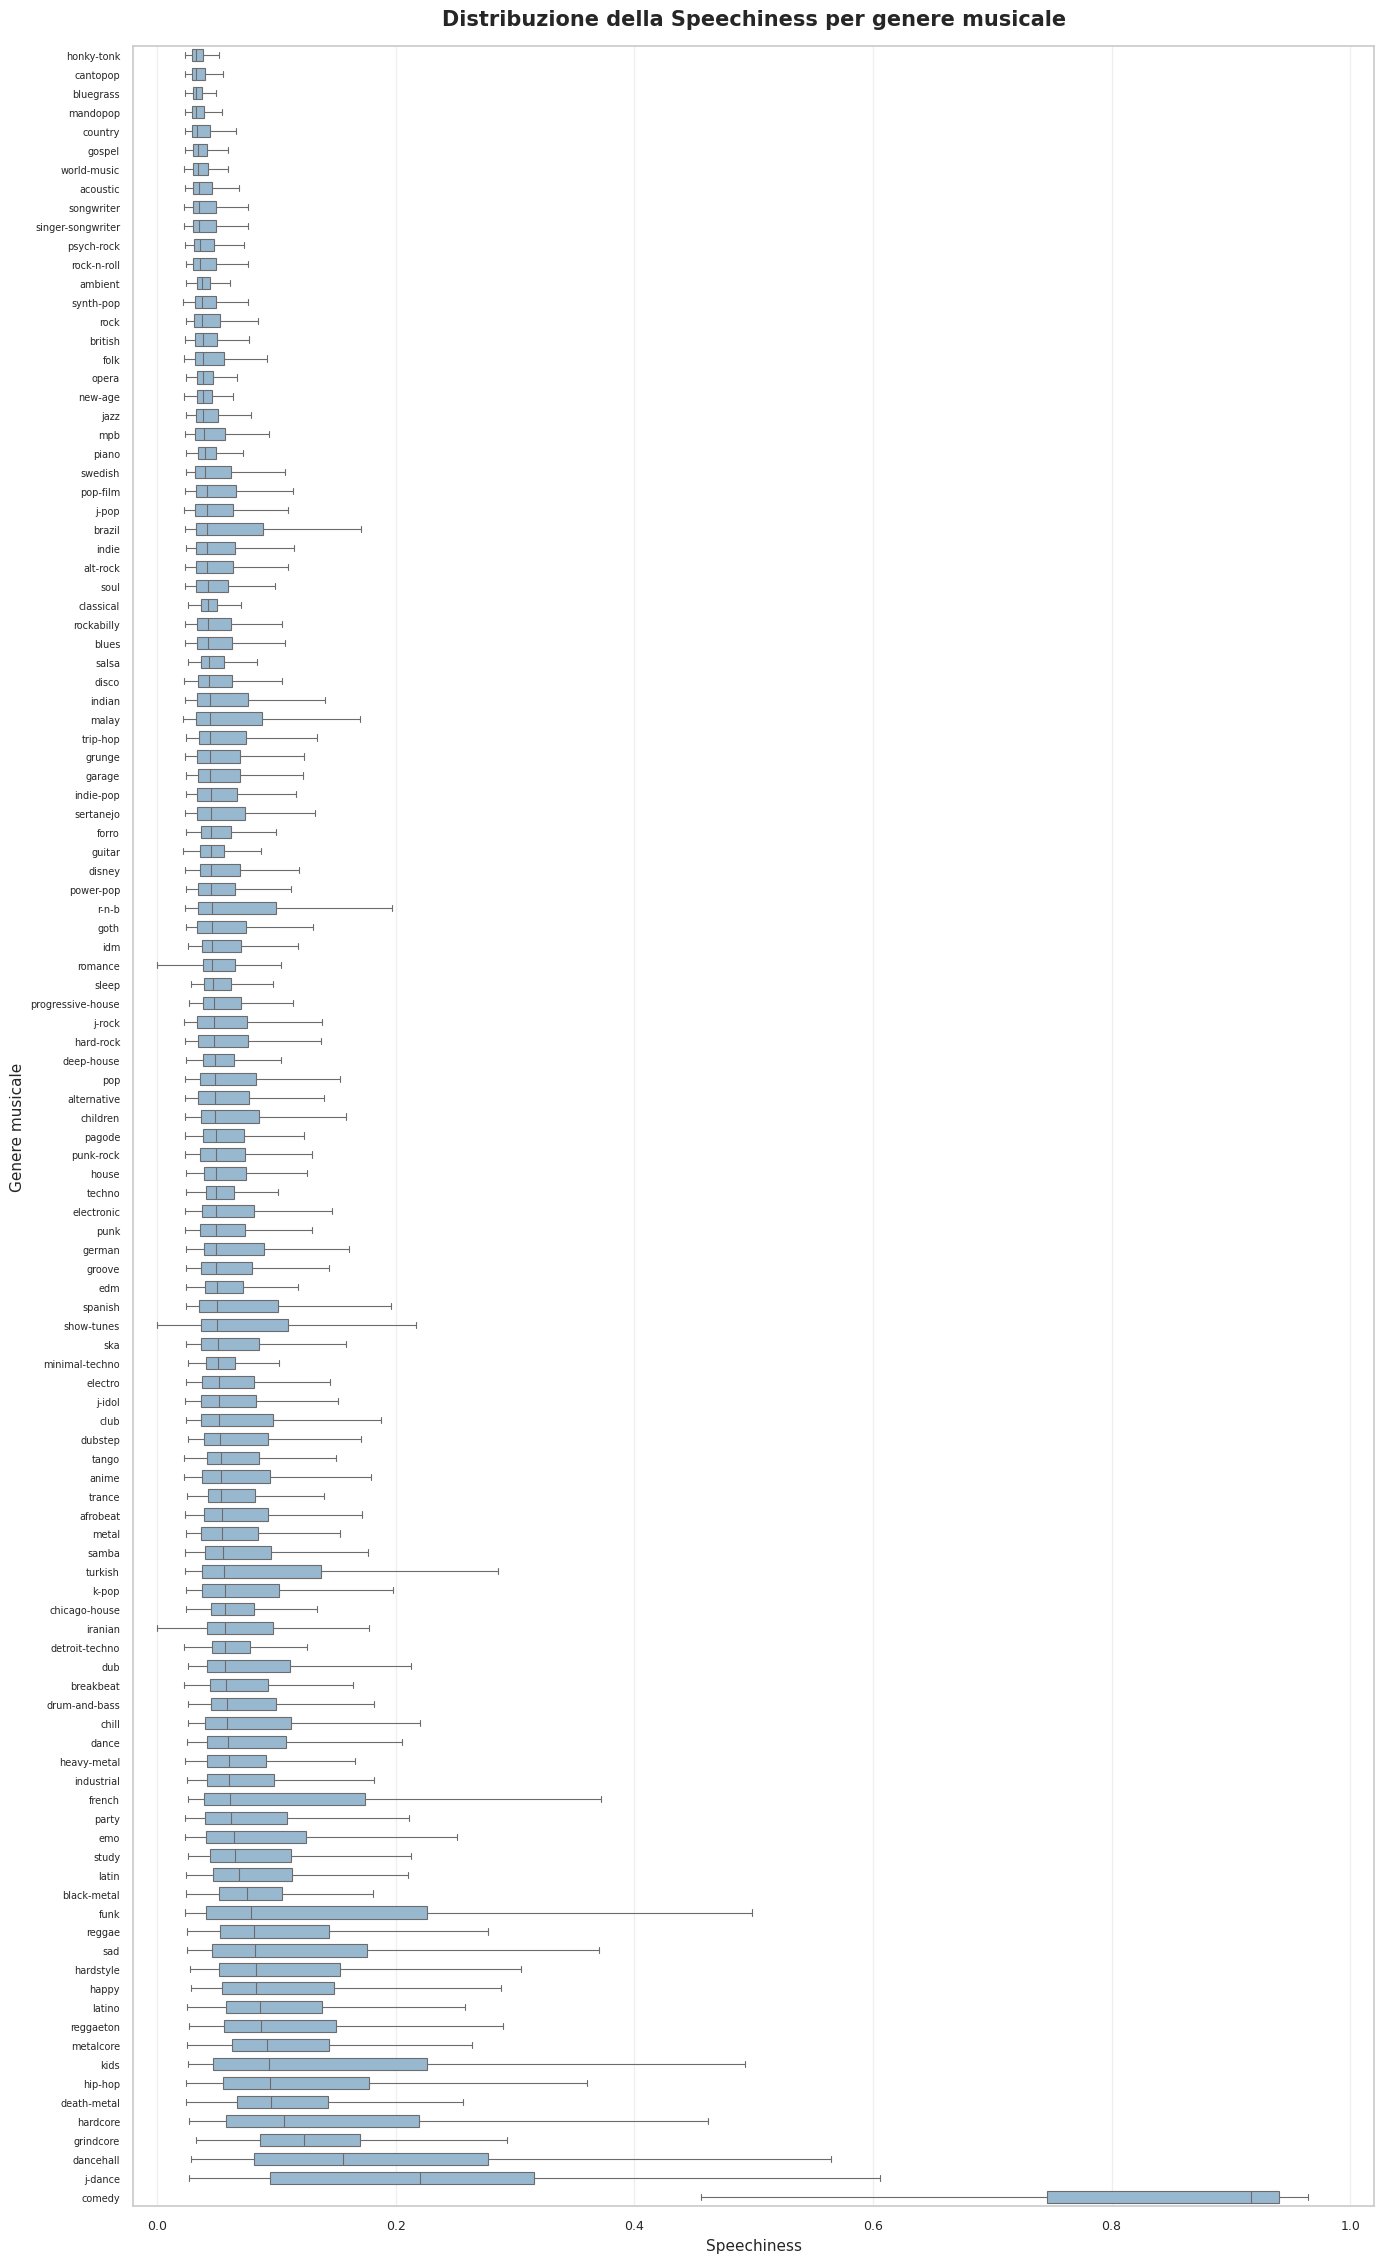

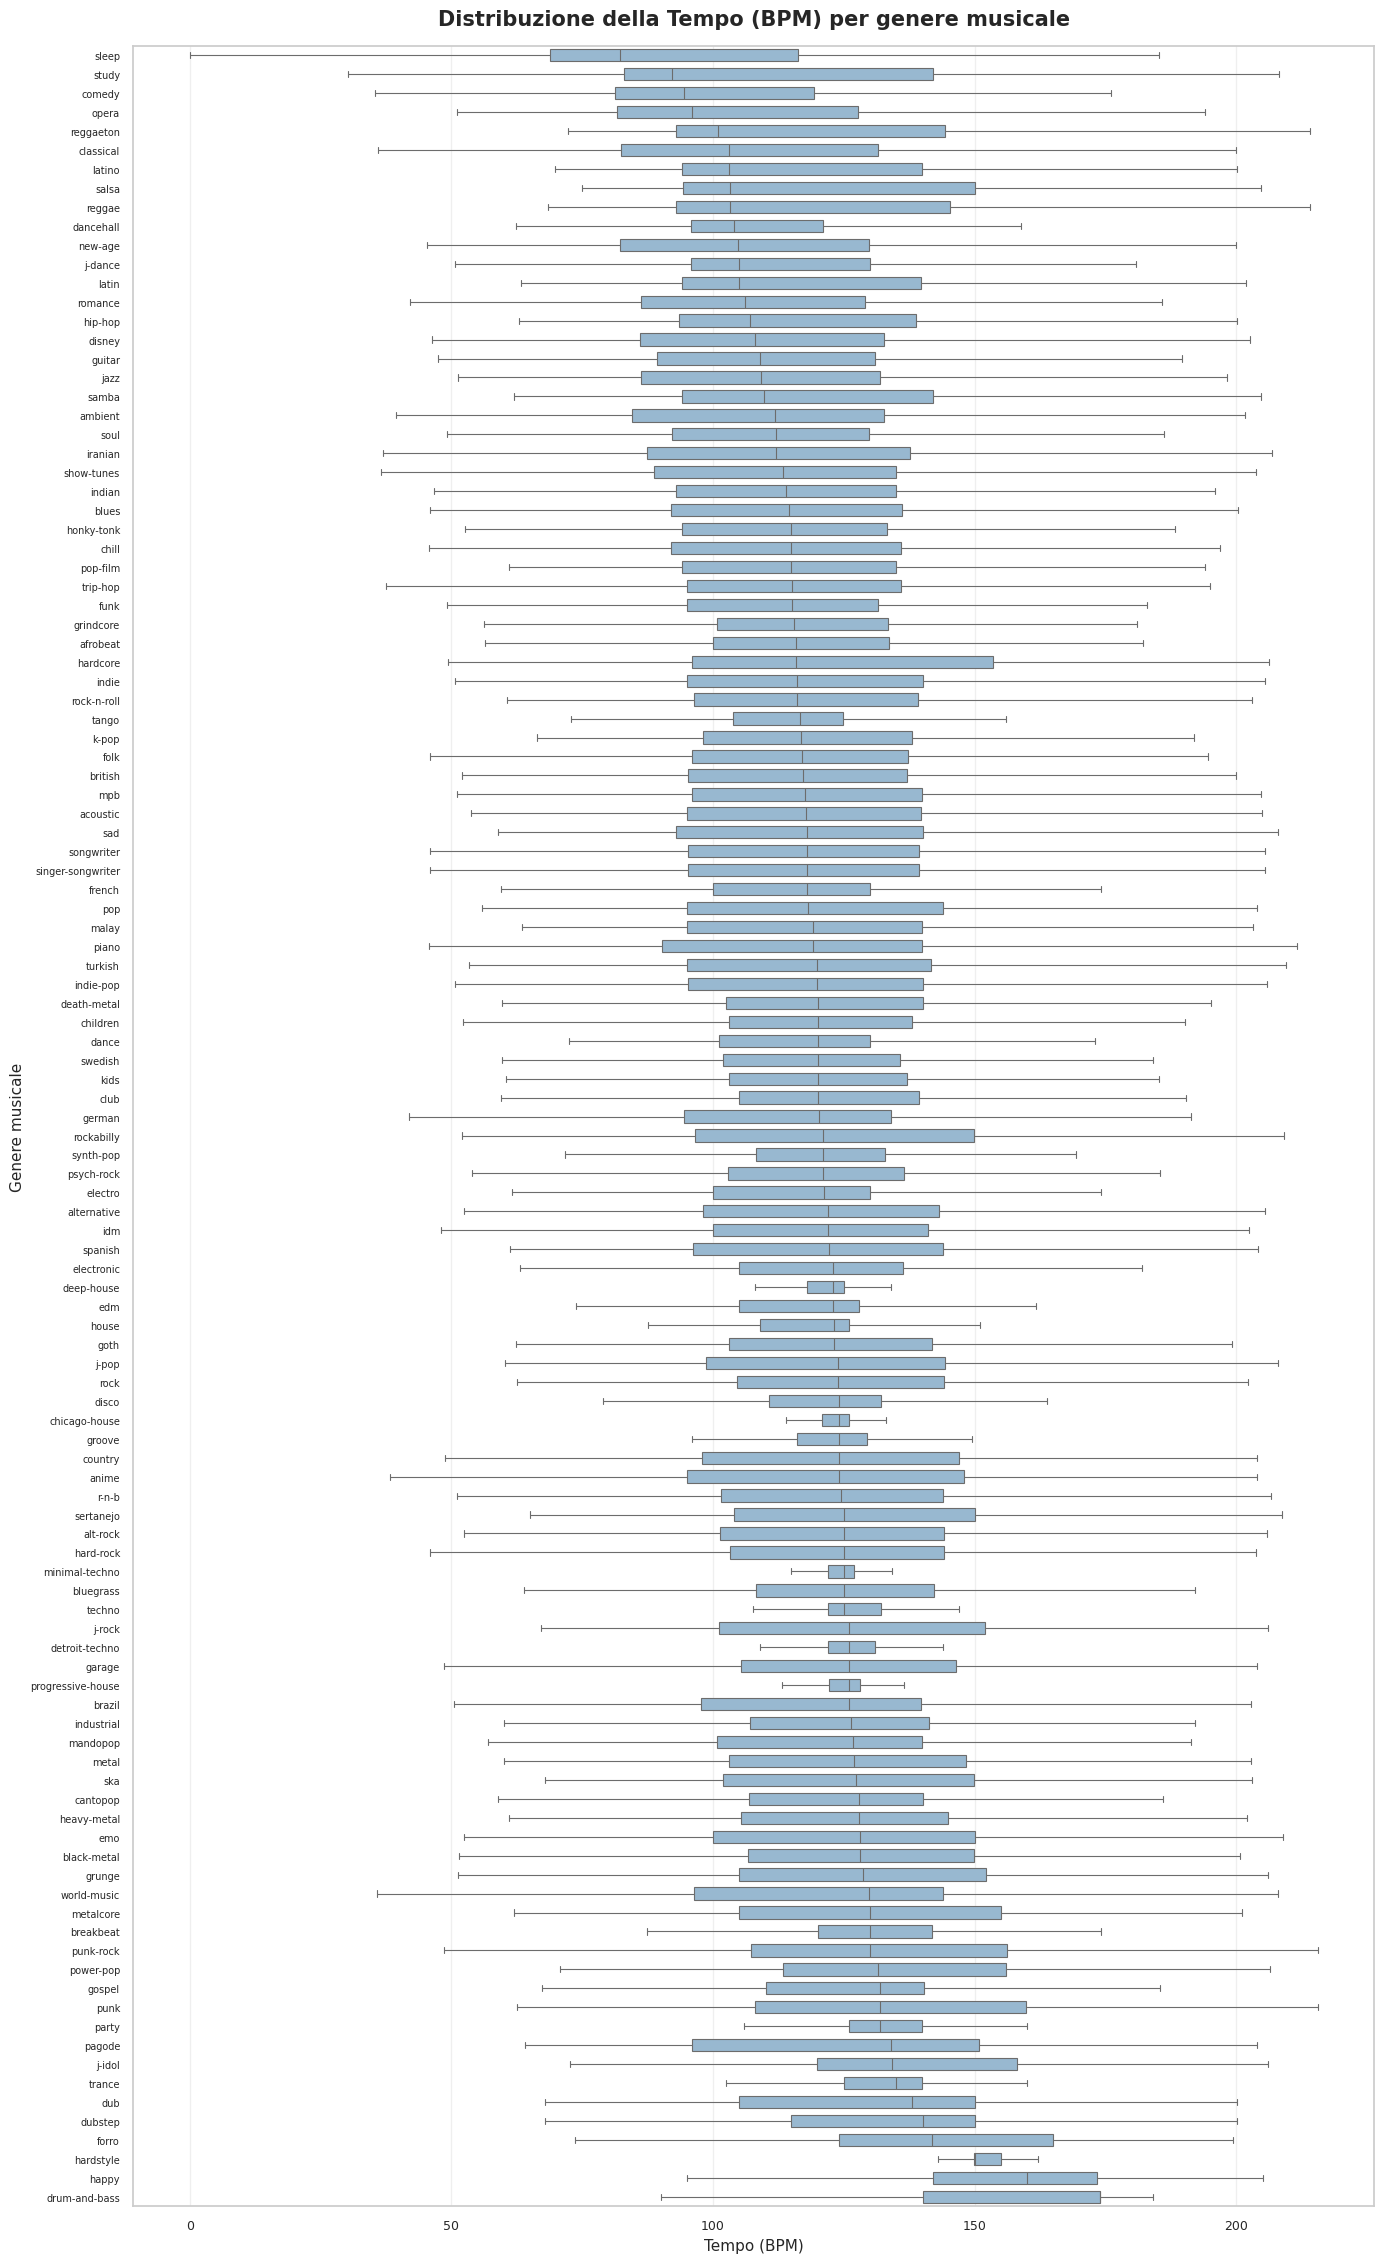

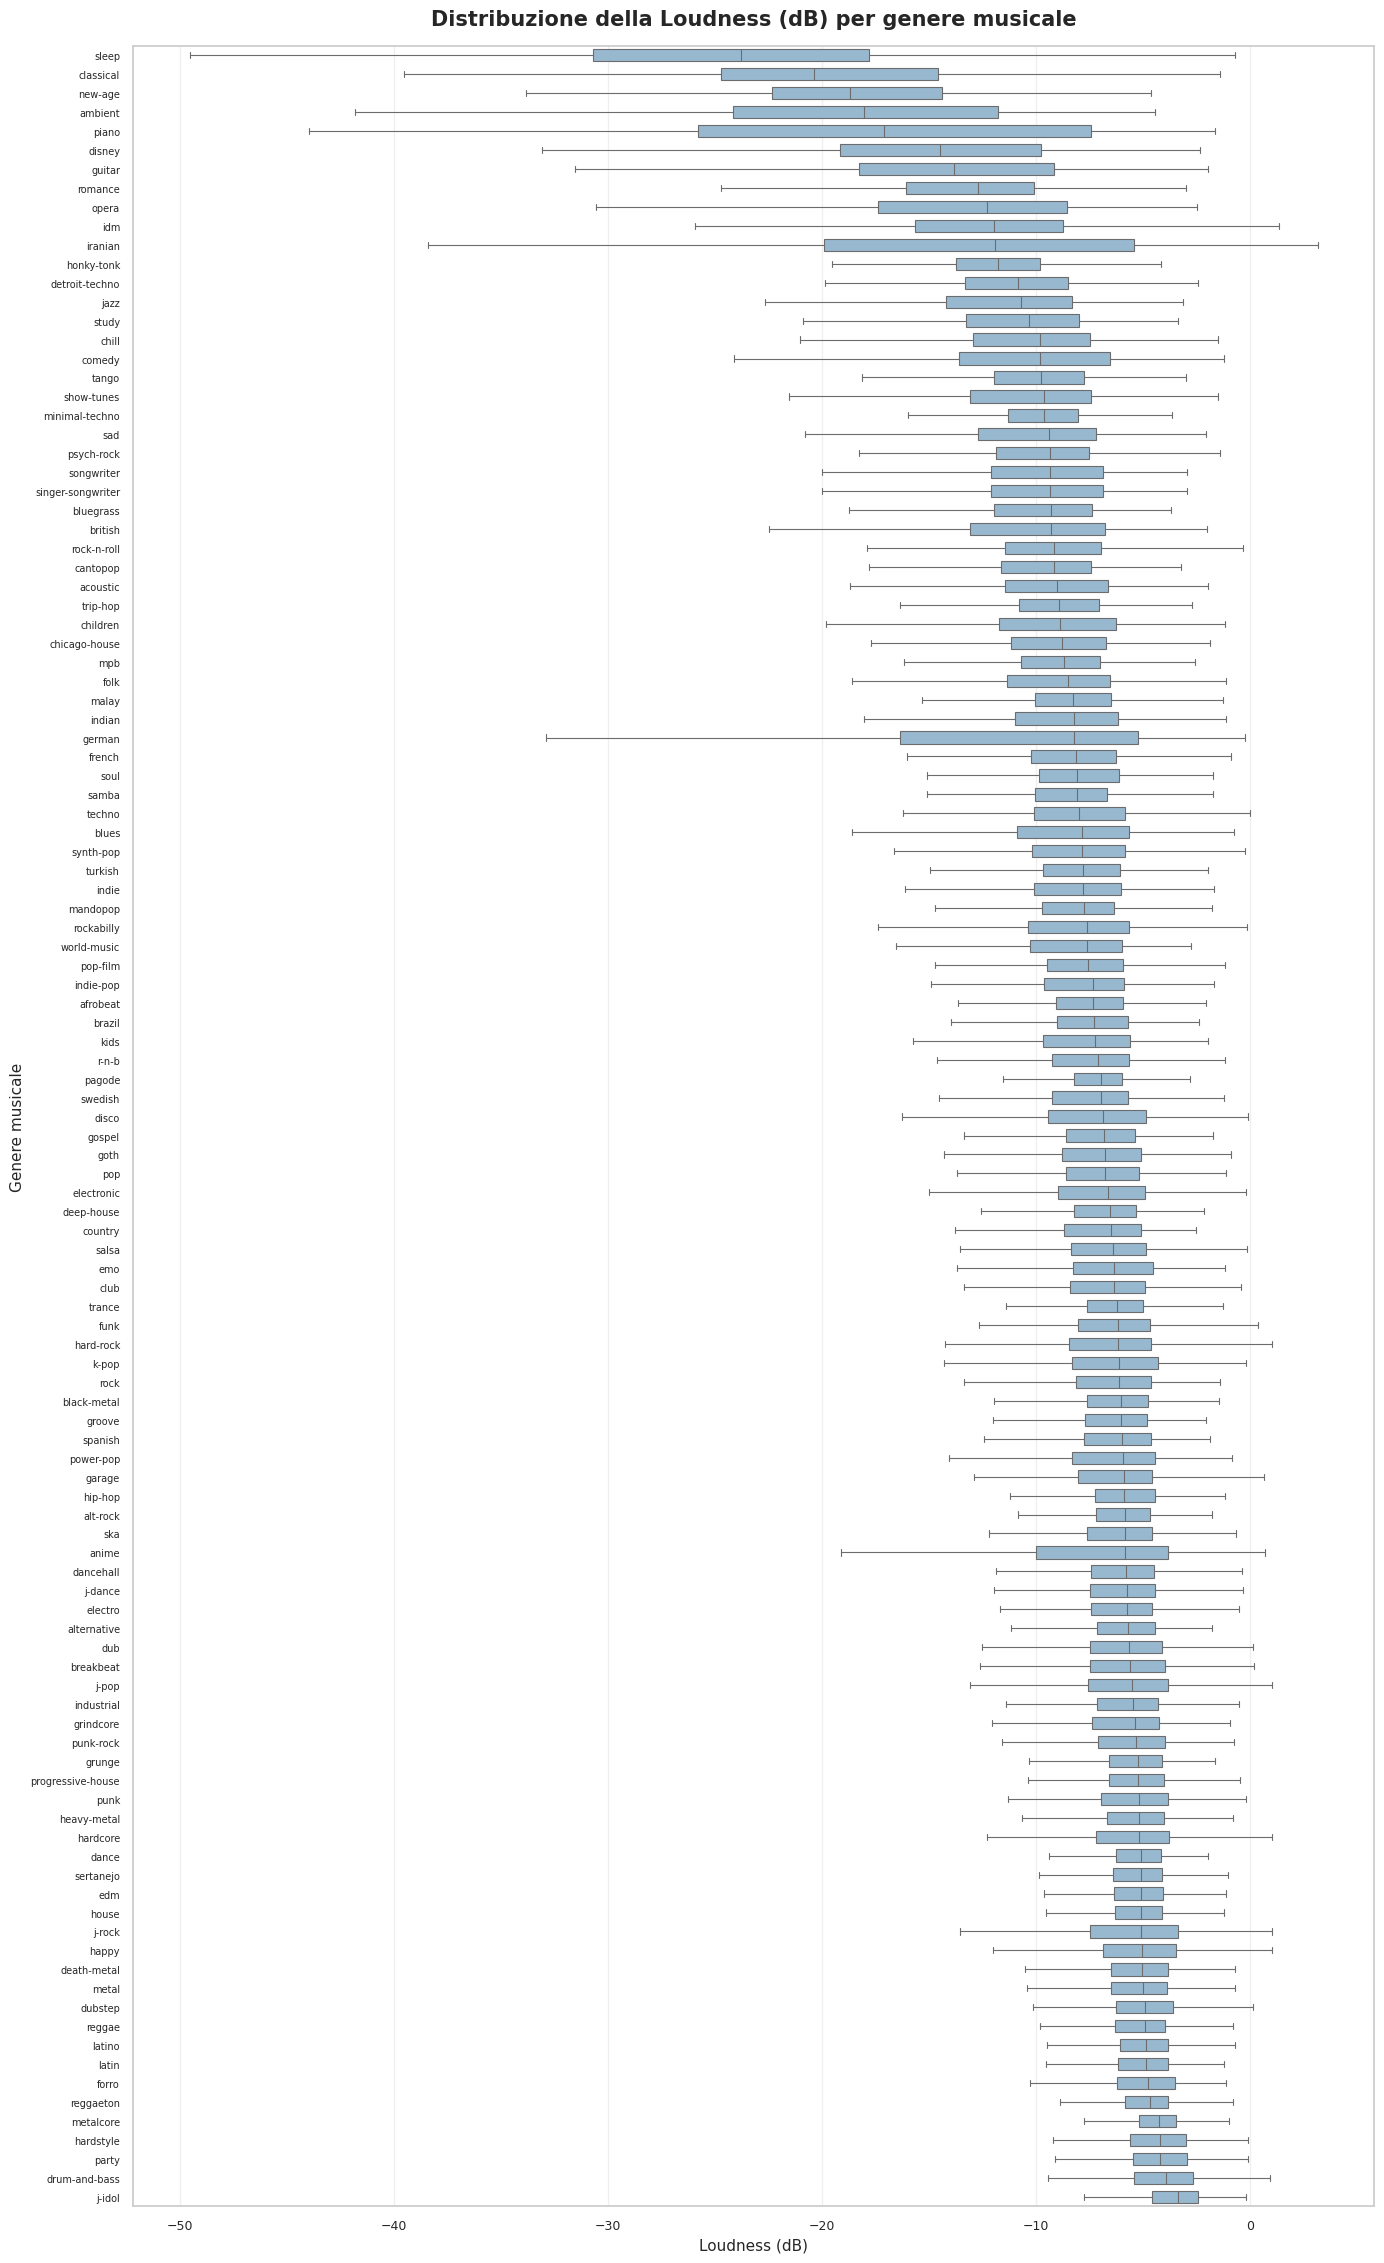

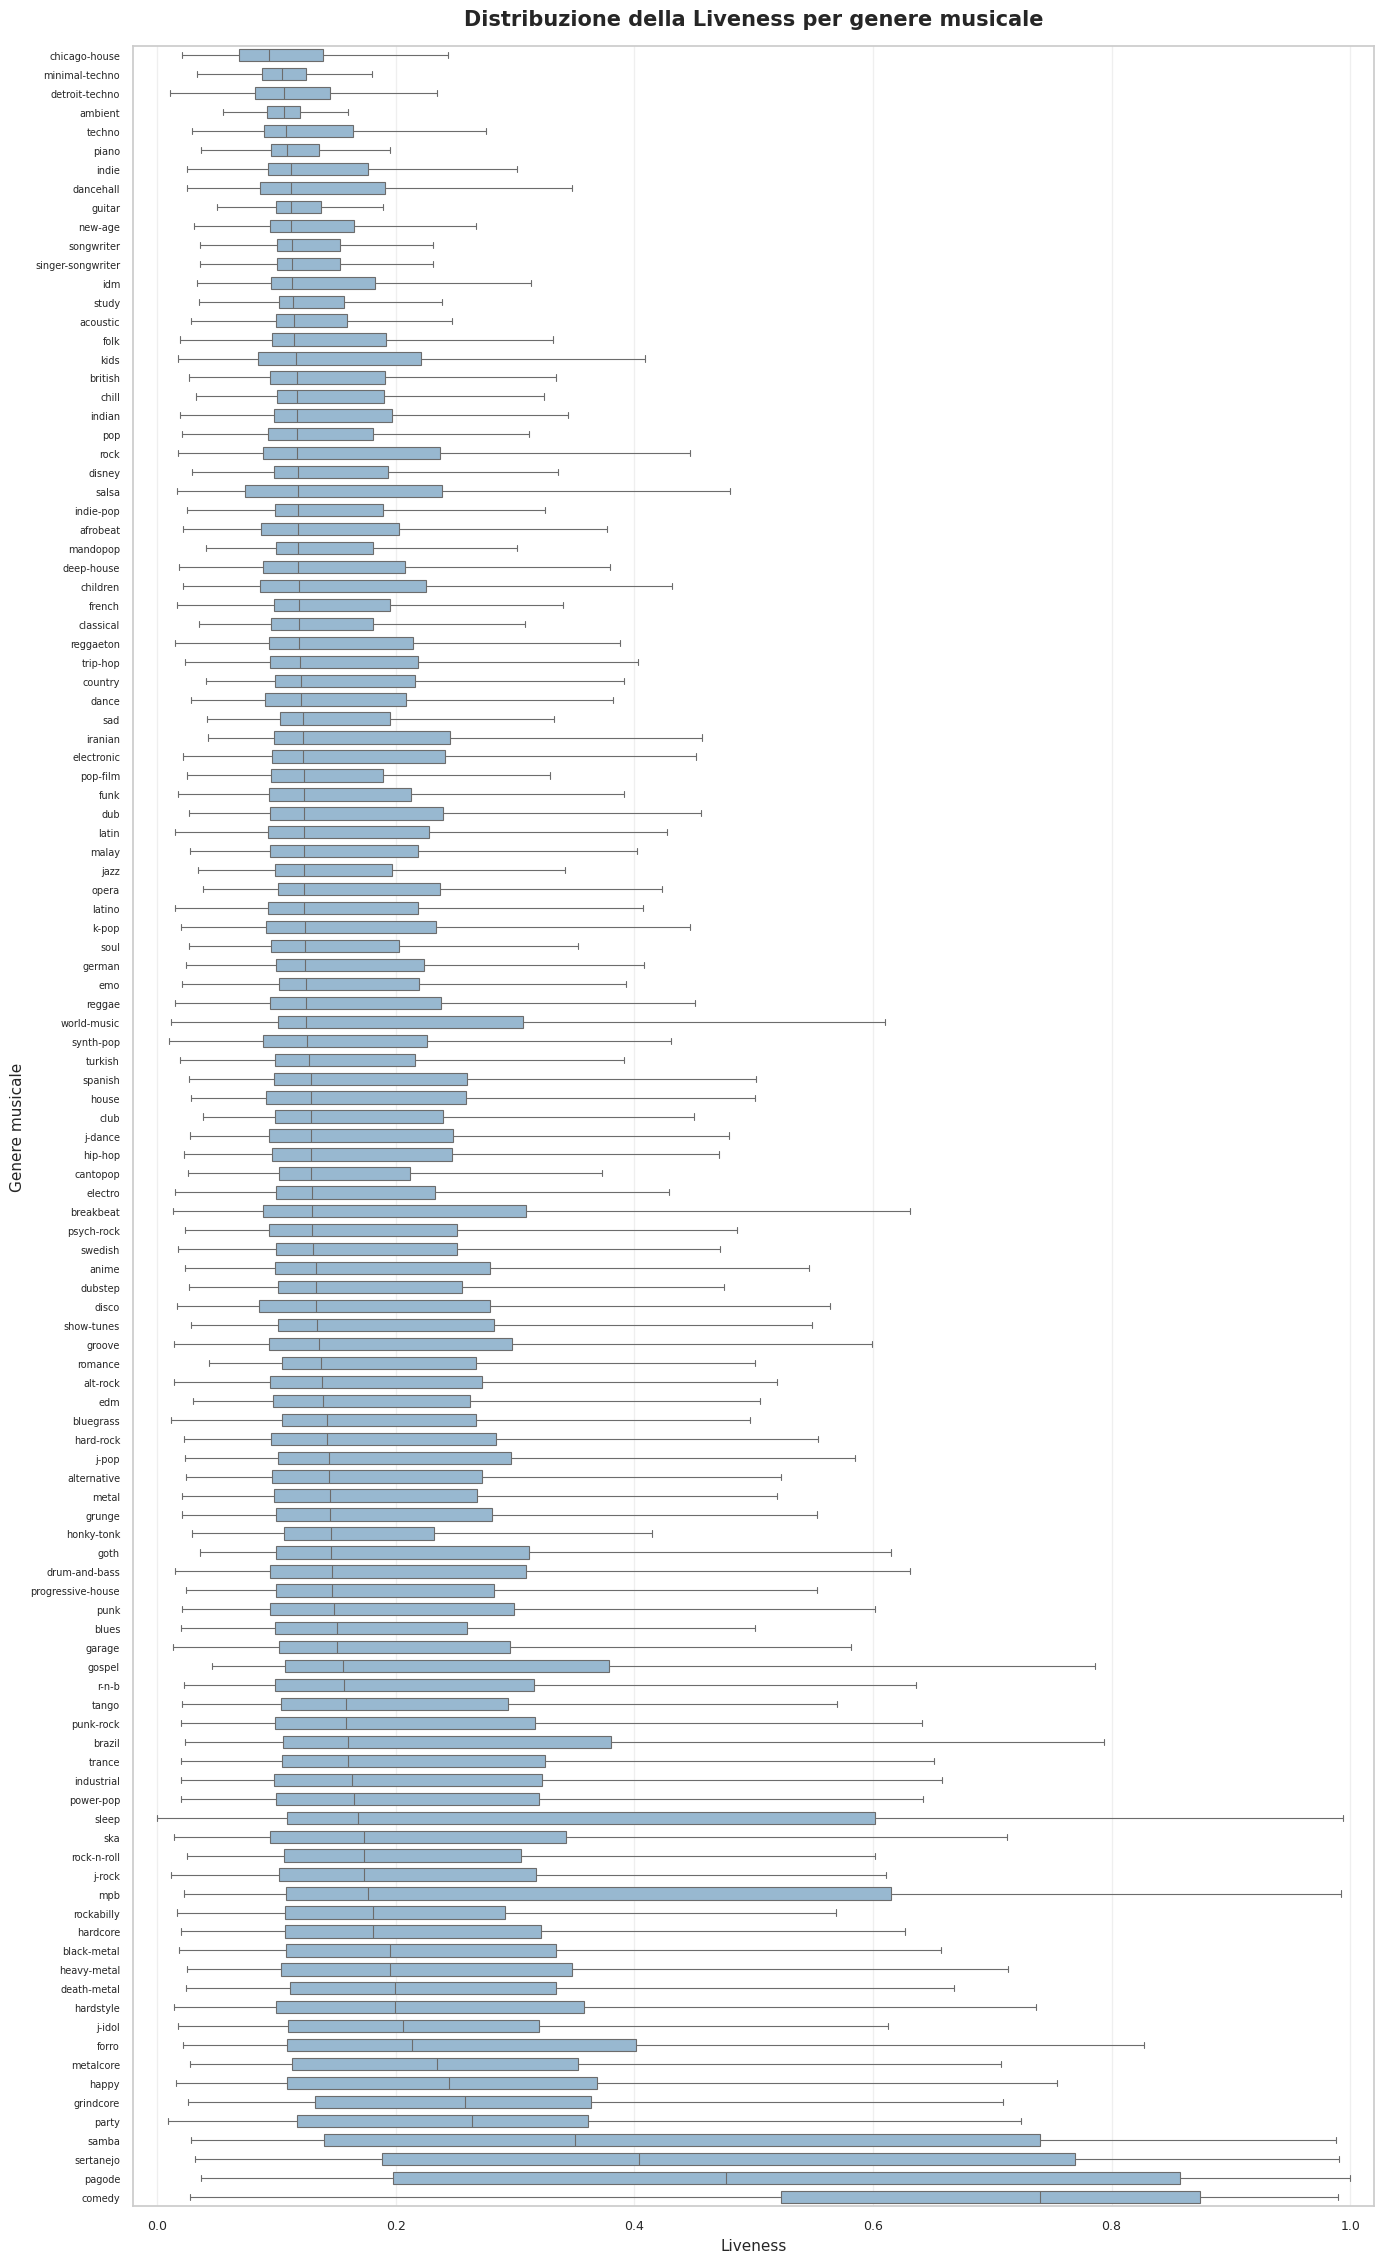


VERIFICA DELLE CARATTERISTICHE AUDIO
--------------------------------
Brani con caratteristiche audio non uniformi: 0

STANDARDIZZAZIONE COMPLETATA
--------------------------------
Medie globali:


,Media
danceability,0.562166
energy,0.634458
valence,0.469477
acousticness,0.328289
instrumentalness,0.173413
speechiness,0.087442
tempo,122.058316
loudness,-8.499004
liveness,0.216970


Deviazioni standard globali:


,Deviazione standard
danceability,0.176690
energy,0.256604
valence,0.262862
acousticness,0.338319
instrumentalness,0.323846
speechiness,0.113276
tempo,30.117364
loudness,5.221460
liveness,0.194883



PROFILI MUSICALI STANDARDIZZATI PER GENERE


,danceability,energy,valence,acousticness,instrumentalness,speechiness,tempo,loudness,liveness
track_genre,,,,,,,,,
acoustic,-0.021,-0.935,-0.363,1.074,-0.535,-0.461,-0.143,-0.097,-0.526
afrobeat,0.729,0.361,0.991,-0.432,-0.510,-0.290,-0.208,0.225,-0.508
alt-rock,-0.108,0.645,0.211,-0.894,-0.535,-0.401,0.097,0.508,-0.405
alternative,-0.012,0.431,0.055,-0.860,-0.535,-0.342,-0.005,0.534,-0.374
ambient,-1.122,-1.779,-1.310,1.752,2.166,-0.441,-0.339,-1.827,-0.569
...,...,...,...,...,...,...,...,...,...
techno,0.774,0.542,-0.808,-0.934,1.740,-0.336,0.098,0.095,-0.559
trance,0.152,0.953,-0.926,-0.951,0.860,-0.299,0.428,0.438,-0.292
trip-hop,0.463,-0.037,0.006,-0.601,0.255,-0.381,-0.233,-0.083,-0.498


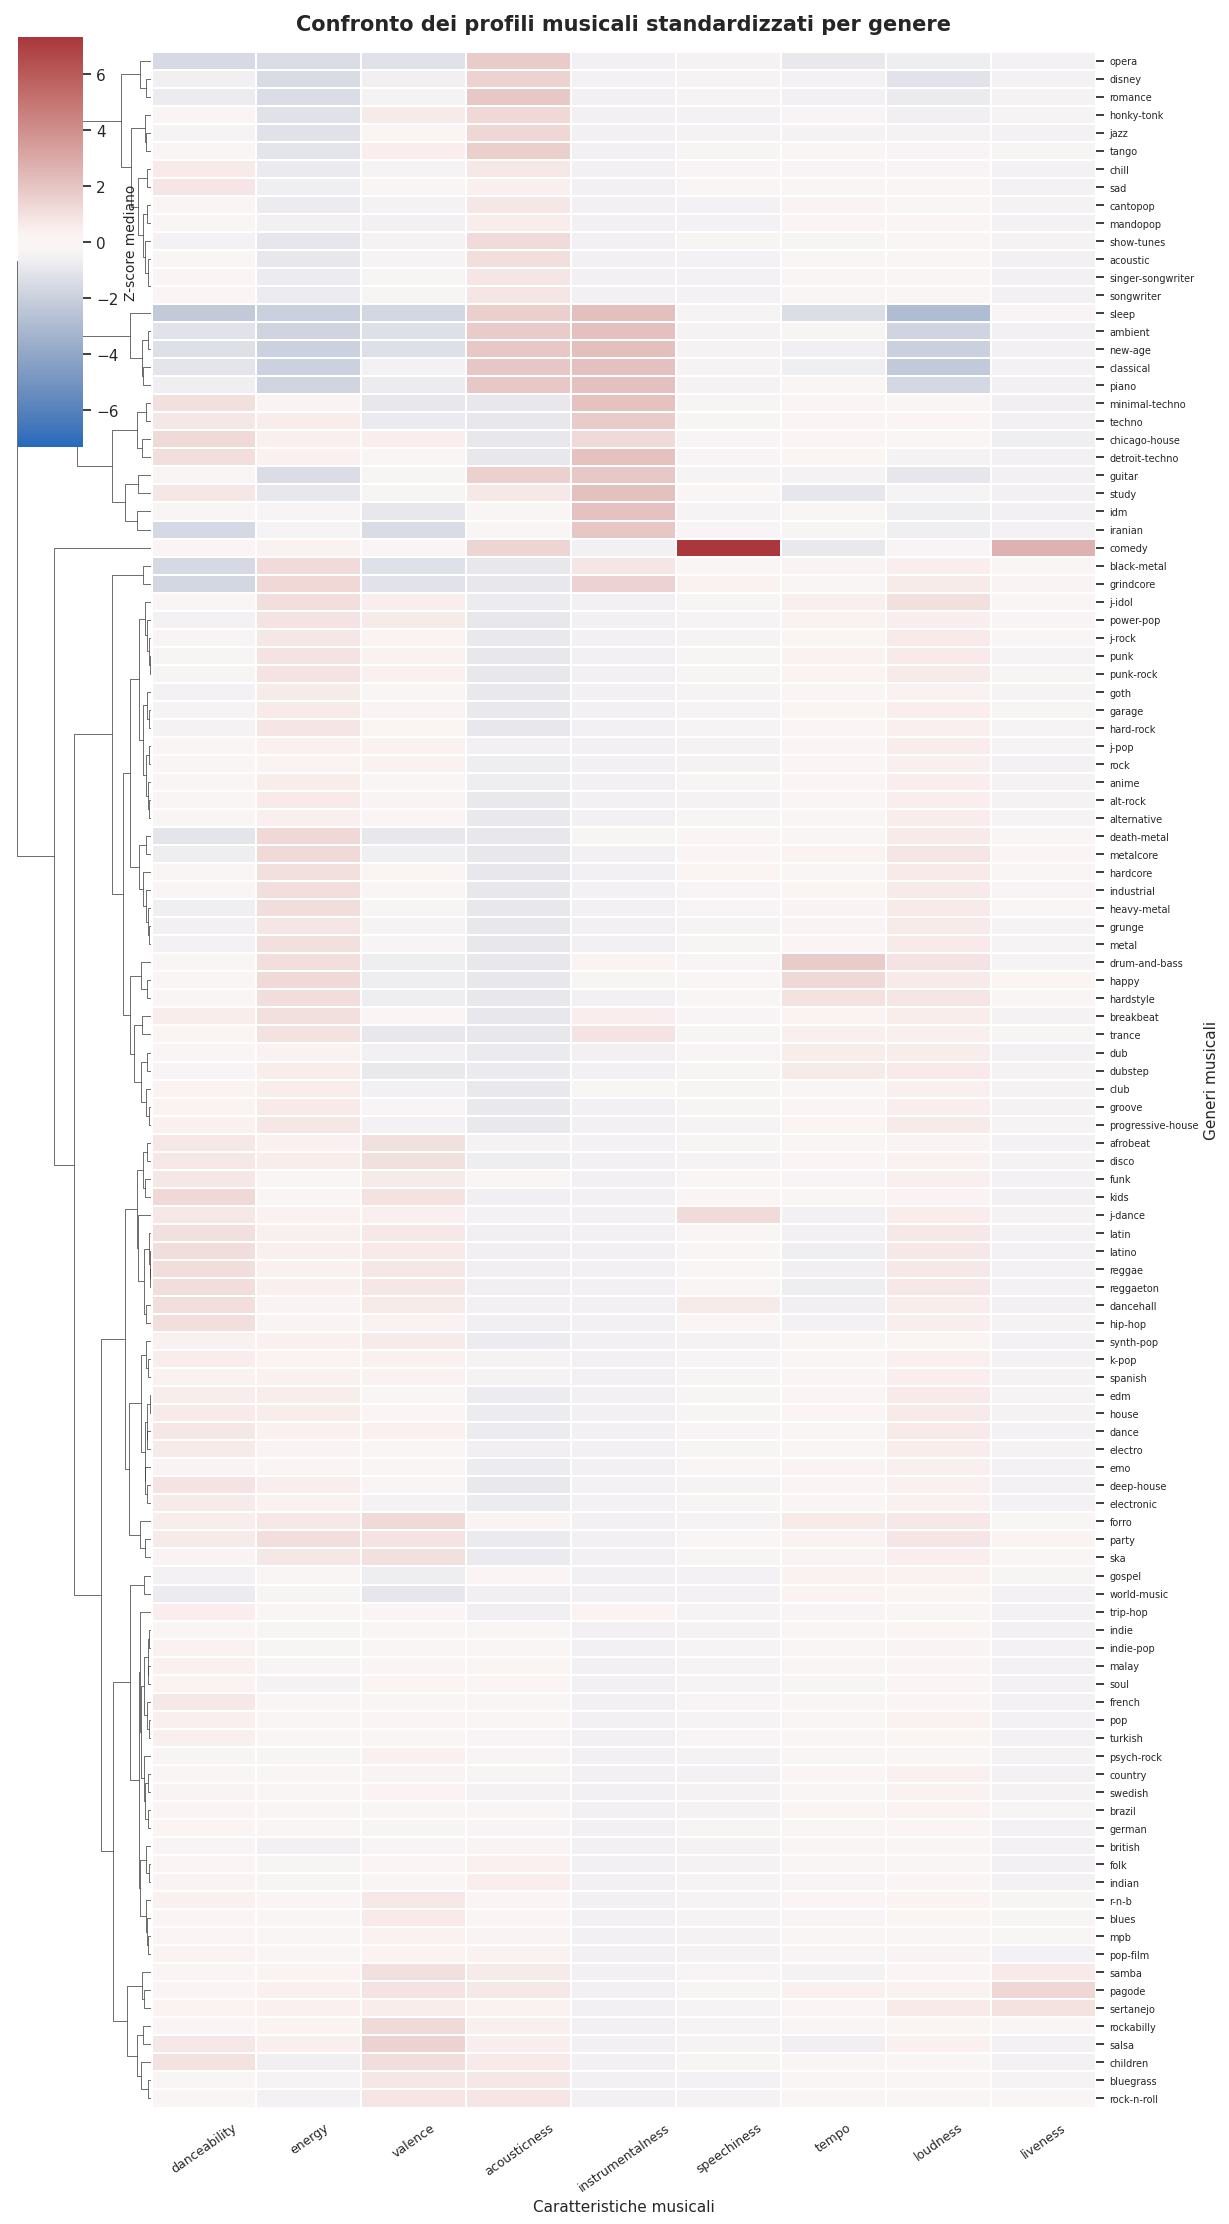


RIEPILOGO DELL'ANALISI
--------------------------------
Generi musicali analizzati nei Box Plot: 114
Generi musicali inclusi nella Heatmap: 114
Caratteristiche audio analizzate: 9
Box Plot generati: 9
Clustered Heatmap generata: 1
Metodo di aggregazione: Mediana
Metodo di standardizzazione: Z-score globale
Metodo di clustering gerarchico: Ward
Metrica di distanza: Euclidea


In [23]:

# ============================================================
# 1. IMPORTAZIONE DELLE LIBRERIE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurazione generale dei grafici
sns.set_theme(style="whitegrid")


# ============================================================
# 2. SELEZIONE DELLE CARATTERISTICHE AUDIO
# ============================================================

# Utilizzo delle nove caratteristiche musicali

caratteristiche_audio = features.copy()

# Nomi da utilizzare nei grafici

nomi_caratteristiche = {
    'danceability': 'Danceability',
    'energy': 'Energy',
    'valence': 'Valence',
    'acousticness': 'Acousticness',
    'instrumentalness': 'Instrumentalness',
    'speechiness': 'Speechiness',
    'tempo': 'Tempo (BPM)',
    'loudness': 'Loudness (dB)',
    'liveness': 'Liveness'
}

# Verifica delle colonne necessarie

colonne_richieste = ['track_id', 'track_genre'] + caratteristiche_audio

colonne_mancanti = [
    col for col in colonne_richieste
    if col not in df_clean.columns
]

if colonne_mancanti:
    raise KeyError(
        f"Colonne mancanti nel dataset: {colonne_mancanti}"
    )


# ============================================================
# 3. PREPARAZIONE DEI DATI
# ============================================================

# Selezione delle colonne necessarie

df_analysis = df_clean[colonne_richieste].copy()

# Normalizzazione delle etichette dei generi

df_analysis['track_genre'] = (
    df_analysis['track_genre']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Rimozione delle etichette mancanti o vuote

df_analysis = df_analysis[
    df_analysis['track_genre'].notna()
    & df_analysis['track_genre'].ne('')
].copy()

# Conversione delle caratteristiche audio in valori numerici

df_analysis[caratteristiche_audio] = (
    df_analysis[caratteristiche_audio]
    .apply(pd.to_numeric, errors='coerce')
)

# Gestione dei valori infiniti

df_analysis[caratteristiche_audio] = (
    df_analysis[caratteristiche_audio]
    .replace([np.inf, -np.inf], np.nan)
)

# Individuazione dei generi presenti

generi = sorted(
    df_analysis['track_genre'].unique().tolist()
)

print("PREPARAZIONE DEI DATI")
print("--------------------------------")
print("Osservazioni disponibili:", len(df_analysis))
print("Brani distinti:", df_analysis['track_id'].nunique())
print("Generi musicali individuati:", len(generi))
print("Caratteristiche audio:", len(caratteristiche_audio))

# Numero di osservazioni disponibili per ogni genere
# e per ogni caratteristica

conteggio_generi = (
    df_analysis
    .groupby('track_genre')[caratteristiche_audio]
    .count()
)

print("\nOSSERVAZIONI DISPONIBILI PER GENERE E CARATTERISTICA")

display(conteggio_generi)


# ============================================================
# 4. NOVE BOXPLOT INDIVIDUALI
# ============================================================

for caratteristica in caratteristiche_audio:

    # Utilizzo delle osservazioni disponibili
    # per la singola caratteristica

    dati_box = df_analysis.dropna(
        subset=[caratteristica]
    ).copy()

    # Ordinamento dei generi in base alla mediana

    ordine_generi = (
        dati_box
        .groupby('track_genre')[caratteristica]
        .median()
        .sort_values()
        .index.tolist()
    )

    # Altezza dinamica in base al numero di generi

    altezza = max(
        10,
        len(ordine_generi) * 0.20
    )

    fig, ax = plt.subplots(
        figsize=(14, altezza)
    )

    # Generazione del Box Plot orizzontale

    sns.boxplot(
        data=dati_box,
        x=caratteristica,
        y='track_genre',
        order=ordine_generi,
        color='#8FBAD9',
        showfliers=False,
        linewidth=0.8,
        width=0.65,
        whis=1.5,
        ax=ax
    )

    # Titolo

    ax.set_title(
        f'Distribuzione della {nomi_caratteristiche[caratteristica]} '
        f'per genere musicale',
        fontsize=15,
        fontweight='bold',
        pad=15
    )

    # Etichette degli assi

    ax.set_xlabel(
        nomi_caratteristiche[caratteristica],
        fontsize=11
    )

    ax.set_ylabel(
        'Genere musicale',
        fontsize=11
    )

    ax.tick_params(
        axis='y',
        labelsize=7
    )

    ax.tick_params(
        axis='x',
        labelsize=9
    )

    # Le caratteristiche comprese tra 0 e 1
    # vengono visualizzate con lo stesso intervallo

    if caratteristica not in ['tempo', 'loudness']:
        ax.set_xlim(-0.02, 1.02)

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.grid(
        axis='y',
        visible=False
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)


# ============================================================
# 5. STANDARDIZZAZIONE DELLE CARATTERISTICHE AUDIO
# ============================================================

# La standardizzazione viene effettuata prima
# dell'aggregazione dei dati per genere.
#
# Per ciascuna caratteristica:
# Z = (valore - media) / deviazione standard
#
# Per calcolare media e deviazione standard utilizziamo
# una sola riga per ogni track_id, evitando di contare
# più volte i brani associati a generi differenti.


# Selezione di una sola riga per ogni brano

df_tracks_audio = df_analysis.drop_duplicates(
    subset='track_id'
).copy()

# Verifica che le caratteristiche audio siano uniformi
# tra le righe associate allo stesso track_id

variazioni = (
    df_analysis
    .groupby('track_id')[caratteristiche_audio]
    .nunique()
)

brani_incoerenti = (
    variazioni.gt(1)
    .any(axis=1)
    .sum()
)

print("\nVERIFICA DELLE CARATTERISTICHE AUDIO")
print("--------------------------------")
print(
    "Brani con caratteristiche audio non uniformi:",
    brani_incoerenti
)

# Calcolo della media di ogni caratteristica
# considerando una sola volta ciascun brano

media_globale = (
    df_tracks_audio[caratteristiche_audio]
    .mean()
)

# Calcolo della deviazione standard globale

deviazione_standard_globale = (
    df_tracks_audio[caratteristiche_audio]
    .std(ddof=0)
)

# Verifica delle caratteristiche senza variabilità

caratteristiche_costanti = (
    deviazione_standard_globale[
        deviazione_standard_globale == 0
    ].index.tolist()
)

if caratteristiche_costanti:
    raise ValueError(
        "Impossibile standardizzare le seguenti caratteristiche "
        f"perché hanno deviazione standard nulla: {caratteristiche_costanti}"
    )

# Standardizzazione dei dati originali

df_standardizzato = (
    df_analysis[caratteristiche_audio]
    - media_globale
) / deviazione_standard_globale

# Associazione dei generi ai valori standardizzati

df_standardizzato['track_genre'] = (
    df_analysis['track_genre']
)

print("\nSTANDARDIZZAZIONE COMPLETATA")
print("--------------------------------")

print("Medie globali:")
display(media_globale.to_frame(name='Media'))

print("Deviazioni standard globali:")
display(
    deviazione_standard_globale.to_frame(
        name='Deviazione standard'
    )
)


# ============================================================
# 6. AGGREGAZIONE DEI DATI PER GENERE
# ============================================================

# Calcolo della mediana dei valori standardizzati
# per ciascun genere musicale

profili_generi = (
    df_standardizzato
    .groupby('track_genre')[caratteristiche_audio]
    .median()
)

# Individuazione di eventuali generi con dati mancanti

generi_incompleti = profili_generi.index[
    profili_generi.isna().any(axis=1)
].tolist()

if generi_incompleti:

    print(
        "\nATTENZIONE: alcuni generi non dispongono "
        "di tutte le caratteristiche."
    )

    print("Generi esclusi dalla Heatmap:", generi_incompleti)

    profili_generi = profili_generi.dropna()

# Verifica del numero minimo di generi

if len(profili_generi) < 2:
    raise ValueError(
        "Non ci sono abbastanza generi completi per il clustering."
    )

print("\nPROFILI MUSICALI STANDARDIZZATI PER GENERE")

display(profili_generi.round(3))


# ============================================================
# 7. CLUSTERED HEATMAP GENERALE
# ============================================================

# Calcolo di una scala cromatica simmetrica rispetto allo zero

limite_colore = max(
    1,
    float(np.abs(profili_generi.to_numpy()).max())
)

# Altezza dinamica in base al numero di generi

altezza = max(
    12,
    len(profili_generi) * 0.20
)

# Generazione della Clustered Heatmap

cluster = sns.clustermap(
    profili_generi,

    # Metodo di clustering
    method='ward',

    # Metrica di distanza
    metric='euclidean',

    # Raggruppamento dei generi
    row_cluster=True,

    # Mantenimento dell'ordine delle caratteristiche
    col_cluster=False,

    # Scala cromatica divergente
    cmap='vlag',

    # Centro della scala cromatica
    center=0,

    # Limiti simmetrici della scala cromatica
    vmin=-limite_colore,
    vmax=limite_colore,

    # Personalizzazione
    linewidths=0.2,
    linecolor='white',

    # Dimensioni
    figsize=(13, altezza),

    # Dimensioni del dendrogramma
    dendrogram_ratio=(0.13, 0.02),

    # Etichette
    xticklabels=True,
    yticklabels=True,

    # Legenda cromatica
    cbar_kws={
        'label': 'Mediana dello Z-score'
    }
)

# Titolo generale

cluster.ax_heatmap.set_title(
    'Confronto dei profili musicali standardizzati per genere',
    fontsize=15,
    fontweight='bold',
    pad=15
)

# Etichette degli assi

cluster.ax_heatmap.set_xlabel(
    'Caratteristiche musicali',
    fontsize=11
)

cluster.ax_heatmap.set_ylabel(
    'Generi musicali',
    fontsize=11
)

# Personalizzazione delle etichette

cluster.ax_heatmap.tick_params(
    axis='x',
    labelrotation=35,
    labelsize=9
)

cluster.ax_heatmap.tick_params(
    axis='y',
    labelrotation=0,
    labelsize=7
)

# Personalizzazione della legenda

cluster.cax.set_ylabel(
    'Z-score mediano',
    fontsize=10
)

# Visualizzazione

plt.show()


# ============================================================
# 8. RIEPILOGO FINALE
# ============================================================

print("\nRIEPILOGO DELL'ANALISI")
print("--------------------------------")

print(
    "Generi musicali analizzati nei Box Plot:",
    len(generi)
)

print(
    "Generi musicali inclusi nella Heatmap:",
    len(profili_generi)
)

print(
    "Caratteristiche audio analizzate:",
    len(caratteristiche_audio)
)

print(
    "Box Plot generati:",
    len(caratteristiche_audio)
)

print("Clustered Heatmap generata: 1")

print("Metodo di aggregazione: Mediana")

print("Metodo di standardizzazione: Z-score globale")

print("Metodo di clustering gerarchico: Ward")

print("Metrica di distanza: Euclidea")


#### 4.1.5 Raggruppamento generi musicali per campioni

L'obiettivo di questa fase è individuare gruppi di generi musicali che presentano profili audio simili e selezionare, per ciascun gruppo, un genere rappresentativo. I generi selezionati costituiranno un campione più contenuto da utilizzare nelle analisi successive.

Il raggruppamento viene effettuato considerando le nove caratteristiche audio già individuate:

- `danceability`
- `energy`
- `valence`
- `acousticness`
- `instrumentalness`
- `speechiness`
- `tempo`
- `loudness`
- `liveness`

La procedura è articolata in cinque fasi: preparazione dei dati, standardizzazione delle caratteristiche, clustering gerarchico dei generi, valutazione e visualizzazione dei gruppi, selezione del genere rappresentativo e costruzione del dataset campione.

**Nota:** questa sezione presuppone che le variabili `df_clean` e `features` siano già state definite nelle celle precedenti del notebook. `df_clean` deve contenere almeno `track_id`, `track_genre` e le caratteristiche audio; `features` deve contenere i nomi delle nove caratteristiche audio.

##### 4.1.5.1 Preparazione e controllo dei dati

Prima di procedere al clustering, vengono isolate le colonne necessarie e controllati i valori mancanti, i valori non numerici e le eventuali incongruenze associate allo stesso `track_id`.

Un brano può comparire nel dataset associato a più generi. Per evitare che le ripetizioni dello stesso identificativo incidano più volte sul calcolo dei parametri di standardizzazione, le statistiche globali vengono calcolate su una tabella con un solo record per `track_id`. In presenza di valori audio discordanti per lo stesso identificativo, viene utilizzata la mediana delle osservazioni disponibili. Le associazioni tra brani e generi vengono invece mantenute: lo stesso brano può quindi contribuire al profilo di più generi, qualora sia etichettato in questo modo nel dataset.

## 4.2 Clustering: individuare gruppi senza utilizzare il genere



### 1. Elbow Method — PRINCIPALE

- **Tipo di grafico:** Line Chart.
- **Dati utilizzati:**
  - Le otto caratteristiche musicali standardizzate.
  - Diversi valori del numero di cluster `K`.
  - Inertia / WCSS calcolata da K-Means (somma dei quadrati delle distanze dei punti dai rispettivi centroidi).

- **Obiettivo:**
  - Analizzare diversi valori di `K`.
  - Osservare come varia l'inerzia all'aumentare del numero di cluster.
  - Individuare un possibile valore di `K` per la suddivisione dei brani.

- **Motivazione:**
  - Il Line Chart permette di rappresentare l'andamento di una misura al variare di un parametro.
  - Consente di osservare come diminuisce la WCSS aumentando il numero di cluster.
  - Permette di individuare il possibile punto di gomito, nel quale l'aggiunta di ulteriori cluster produce una riduzione dell'inerzia progressivamente meno significativa.
  - Il grafico fornisce un primo criterio per scegliere il numero di gruppi, evitando una scelta completamente arbitraria.

### 2. Silhouette Score — PRINCIPALE

- **Tipo di grafico:** Line Chart.
- **Dati utilizzati:**
  - Le otto caratteristiche musicali standardizzate.
  - Diversi valori del numero di cluster `K`.
  - Silhouette Score calcolato per ciascun valore di `K`.

- **Obiettivo:**
  - Valutare la qualità della suddivisione dei dati in cluster.
  - Analizzare quanto i brani appartenenti allo stesso gruppo siano simili tra loro.
  - Valutare quanto i cluster siano separati dagli altri gruppi.
  - Confrontare diverse configurazioni di `K`.

- **Motivazione:**
  - Il Line Chart permette di confrontare il Silhouette Score ottenuto con diversi valori di `K`.
  - La rappresentazione a linee rende immediatamente visibili gli aumenti e le diminuzioni del punteggio.
  - Il Silhouette Score considera sia la coesione interna dei gruppi sia la loro separazione dagli altri cluster.
  - Questa visualizzazione completa l'Elbow Method, offrendo un secondo criterio per valutare il numero di cluster più adeguato.

### 3. Visualizzazione dei cluster tramite PCA — PRINCIPALE

- **Tipo di grafico:** Scatter Plot.
- **Dati utilizzati:**
  - Le otto caratteristiche musicali standardizzate.
  - Le etichette dei cluster assegnate da K-Means.
  - Le prime due componenti principali ottenute tramite PCA.

- **Obiettivo:**
  - Rappresentare visivamente i gruppi individuati dall'algoritmo.
  - Osservare se i cluster appaiono distinti oppure sovrapposti.
  - Individuare eventuali gruppi vicini tra loro.

- **Motivazione:**
  - Lo Scatter Plot permette di rappresentare le singole osservazioni attraverso punti distribuiti in uno spazio bidimensionale.
  - Ogni punto rappresenta un brano musicale, mentre il colore identifica il cluster di appartenenza.
  - La PCA permette di ridurre le otto caratteristiche originali a due componenti principali, rendendo possibile la visualizzazione dei dati in due dimensioni.
  - Questa rappresentazione facilita l'osservazione della distribuzione dei brani e delle eventuali separazioni o sovrapposizioni tra i gruppi.

### 4. Profilo musicale dei cluster — PRINCIPALE

- **Tipo di grafico:** Heatmap.
- **Dati utilizzati:**
  - Etichette `cluster` ottenute da K-Means.
  - Le otto caratteristiche musicali.
  - Valore medio di ciascuna caratteristica per ogni cluster.

- **Obiettivo:**
  - Analizzare le caratteristiche musicali medie di ciascun cluster.
  - Individuare le variabili che contraddistinguono maggiormente ogni gruppo.
  - Attribuire un'interpretazione musicale ai cluster individuati.

- **Motivazione:**
  - La Heatmap permette di rappresentare contemporaneamente più caratteristiche per ciascun cluster attraverso una matrice di colori.
  - La variazione cromatica facilita il confronto tra i valori medi delle diverse caratteristiche musicali.
  - Consente di individuare rapidamente quali proprietà risultano maggiormente presenti o meno rappresentate in ciascun gruppo.
  - Questa visualizzazione permette di interpretare musicalmente i cluster, andando oltre la semplice rappresentazione dei punti nello Scatter Plot.

### 5. Confronto tra cluster e generi musicali — PRINCIPALE

- **Tipo di grafico:** Heatmap.
- **Dati utilizzati:**
  - `cluster` assegnato da K-Means.
  - `track_genre` originale.
  - Conteggi e percentuali per ogni combinazione cluster-genere.

- **Obiettivo:**
  - Confrontare i cluster individuati autonomamente con i generi musicali originali.
  - Osservare quali generi sono presenti in ciascun cluster.
  - Individuare generi distribuiti in più cluster.
  - Individuare cluster che contengono brani appartenenti a generi differenti.
  - Analizzare quanto i gruppi acustici corrispondono alle categorie musicali originali.

- **Motivazione:**
  - La Heatmap permette di rappresentare la relazione tra due variabili categoriali: cluster e genere musicale.
  - L'utilizzo dei colori evidenzia quali combinazioni cluster-genere sono più frequenti.
  - Le percentuali per riga consentono di osservare la composizione interna di ciascun cluster, facilitando il confronto tra gruppi di dimensioni differenti.
  - Questa visualizzazione è fondamentale per rispondere alla domanda di ricerca, perché permette di verificare se i brani raggruppati in base alle caratteristiche acustiche corrispondono ai generi originali oppure se generi diversi vengono riuniti negli stessi cluster.



## 4.3 Classificazione supervisionata: prevedere il genere musicale — FACOLTATIVA

Questa fase costituisce un approfondimento rispetto all'obiettivo principale. A differenza del clustering, che individua gruppi senza conoscere in anticipo i generi, la classificazione supervisionata utilizza le etichette originali come variabile da prevedere.

### 1. Decision Tree — FACOLTATIVO

- **Tipo di visualizzazione:** Albero decisionale (Decision Tree).
- **Dati utilizzati:**
  - Input: le otto caratteristiche musicali.
  - Target: `track_genre`.

- **Obiettivo:**
  - Costruire un modello in grado di prevedere il genere musicale di un brano.
  - Osservare quali caratteristiche vengono utilizzate durante le decisioni.
  - Comprendere le regole utilizzate dal modello per classificare le tracce.

- **Motivazione:**
  - L'albero decisionale rappresenta le regole di classificazione attraverso nodi e rami.
  - Permette di seguire il percorso delle decisioni e comprendere quali caratteristiche vengono utilizzate per assegnare un genere a un brano.
  - È una visualizzazione interpretabile, utile per comprendere il funzionamento del modello e confrontare i risultati con quelli ottenuti attraverso il clustering.

### 2. Feature Importance — FACOLTATIVO

- **Tipo di grafico:** Bar Chart orizzontale.
- **Dati utilizzati:**
  - Modello Random Forest.
  - Le otto caratteristiche musicali.
  - Valori di Feature Importance.

- **Obiettivo:**
  - Individuare le caratteristiche musicali più informative per la classificazione.
  - Ordinare le variabili in base alla loro importanza.
  - Comprendere quali proprietà musicali contribuiscono maggiormente alle previsioni del modello.

- **Motivazione:**
  - Il grafico a barre permette di confrontare e ordinare facilmente l'importanza delle diverse caratteristiche.
  - L'orientamento orizzontale facilita la lettura dei nomi delle variabili.
  - Consente di individuare rapidamente quali caratteristiche risultano più utili al modello per distinguere i generi musicali.

### 3. Confronto Decision Tree vs Random Forest — FACOLTATIVO

- **Tipo di grafico:** Bar Chart comparativo.
- **Dati utilizzati:**
  - Risultati del Decision Tree.
  - Risultati della Random Forest.
  - Metriche di valutazione calcolate sullo stesso test set.

- **Obiettivo:**
  - Confrontare le prestazioni dei due algoritmi.
  - Individuare quale modello ottiene risultati migliori nella previsione dei generi.
  - Valutare se un modello più complesso offre un miglioramento rispetto a un singolo albero decisionale.

- **Motivazione:**
  - Il grafico a barre permette di confrontare direttamente le prestazioni dei due modelli.
  - Utilizzando la stessa scala è possibile osservare facilmente le differenze tra i risultati.
  - Offre una rappresentazione immediata delle prestazioni dei modelli di classificazione.

### 4. Confusion Matrix — FACOLTATIVO

- **Tipo di grafico:** Confusion Matrix / Heatmap.
- **Dati utilizzati:**
  - Generi reali presenti nel test set.
  - Generi previsti dal modello.
  - Risultati del Decision Tree o della Random Forest.

- **Obiettivo:**
  - Osservare quali generi vengono classificati correttamente.
  - Individuare quali generi vengono confusi tra loro.
  - Analizzare eventuali difficoltà nella distinzione tra categorie musicali.

- **Motivazione:**
  - La Heatmap permette di rappresentare il confronto tra le classi reali e quelle previste dal modello.
  - L'utilizzo dei colori rende immediatamente visibili le classificazioni corrette e gli errori.
  - Consente di individuare quali generi vengono confusi più frequentemente e di approfondire i limiti del modello.


# 5. Preprocessing e normalizzazione


5.1 Selezione delle caratteristiche

5.2 Pulizia e preparazione dei dati

5.3 Standardizzazione delle variabili

5.4 Dataset finale per il clustering


# 6. Applicazione dell'algoritmo di clustering


6.1 Introduzione e scelta dell'algoritmo



6.2 Scelta del numero di cluster
- 6.2.1 Elbow Method
- 6.2.2 Silhouette Score



6.3 Applicazione di K-Means



6.4 Valutazione del clustering


# 7. Interpretazione e visualizzazione dei risultati


7.1 Visualizzazione tramite PCA



7.2 Profilo musicale dei cluster



7.3 Confronto tra cluster e generi musicali



7.4 Interpretazione dei risultati



7.5 Eventuali approfondimenti (facoltativi)


# 8. Conclusioni e limiti


8.1 Risultati principali



8.2 Risposta alla domanda di ricerca



8.3 Limiti dell'analisi



8.4 Possibili sviluppi futuri
